In [1]:
# CELL 1 — Mount Google Drive

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [2]:
# CELL 2 — Define Project Paths

import os

BASE = "/content/drive/MyDrive"

DRIVE_PREPROCESSED = os.path.join(
    BASE,
    "Alzheimer_Preprocessed"
)

LOCAL_PREPROCESSED = "/content/Alzheimer_Preprocessed"

TRAINING_DIR = os.path.join(
    BASE,
    "Alzheimer_Training"
)

METADATA_PATH = os.path.join(
    BASE,
    "metadata_subjectwise_split.csv"
)

BASELINE_CHECKPOINT = os.path.join(
    TRAINING_DIR,
    "best_mri_resnet18.pth"
)

PARTIAL_CHECKPOINT = os.path.join(
    TRAINING_DIR,
    "best_mri_resnet18_partial_ft.pth"
)

print("Drive preprocessed:", DRIVE_PREPROCESSED)
print("Local preprocessed:", LOCAL_PREPROCESSED)
print("Training directory:", TRAINING_DIR)
print("Metadata:", METADATA_PATH)
print("Baseline checkpoint:", BASELINE_CHECKPOINT)

print("\nPath checks:")
print("Preprocessed exists:", os.path.exists(DRIVE_PREPROCESSED))
print("Metadata exists:", os.path.exists(METADATA_PATH))
print("Baseline checkpoint exists:", os.path.exists(BASELINE_CHECKPOINT))

Drive preprocessed: /content/drive/MyDrive/Alzheimer_Preprocessed
Local preprocessed: /content/Alzheimer_Preprocessed
Training directory: /content/drive/MyDrive/Alzheimer_Training
Metadata: /content/drive/MyDrive/metadata_subjectwise_split.csv
Baseline checkpoint: /content/drive/MyDrive/Alzheimer_Training/best_mri_resnet18.pth

Path checks:
Preprocessed exists: True
Metadata exists: True
Baseline checkpoint exists: True


In [3]:
# CELL 3 — Check GPU

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("WARNING: CUDA is not available.")

print("Device:", DEVICE)

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda


In [ ]:
# CELL A — Unmount Google Drive

from google.colab import drive

try:
    drive.flush_and_unmount()
    print("Google Drive unmounted successfully.")
except Exception as e:
    print("Unmount message:", e)

Google Drive unmounted successfully.


In [ ]:
# CELL B — Remount Google Drive

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=True
)

print("Google Drive remounted successfully.")

Mounted at /content/drive
Google Drive remounted successfully.


In [6]:
# CELL C — Test Google Drive connection

import os

DRIVE_PREPROCESSED = (
    "/content/drive/MyDrive/Alzheimer_Preprocessed"
)

print(
    "Dataset folder exists:",
    os.path.exists(DRIVE_PREPROCESSED)
)

for split in ["train", "validation", "test"]:

    path = os.path.join(
        DRIVE_PREPROCESSED,
        split
    )

    print(
        split,
        "exists:",
        os.path.exists(path)
    )

    if os.path.exists(path):

        files = [
            f for f in os.listdir(path)
            if f.endswith(".npz")
        ]

        print(
            "  NPZ files:",
            len(files)
        )

Dataset folder exists: True
train exists: True
  NPZ files: 443
validation exists: True
  NPZ files: 95
test exists: True
  NPZ files: 92


In [ ]:
# CELL D — Test a single NPZ file

import os
import numpy as np

train_dir = os.path.join(
    DRIVE_PREPROCESSED,
    "train"
)

files = sorted([
    f for f in os.listdir(train_dir)
    if f.endswith(".npz")
])

test_file = os.path.join(
    train_dir,
    files[0]
)

print("Testing:")
print(test_file)

with np.load(
    test_file,
    allow_pickle=False
) as npz:

    print("Keys:", npz.files)

    if "data" in npz:
        arr = npz["data"]
    else:
        arr = npz["images"]

    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)

print("Single-file read successful.")

Testing:
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I101406.npz
Keys: ['images', 'selected_slices', 'image_id', 'subject', 'group', 'split']
Shape: (32, 224, 224, 3)
Dtype: float32
Single-file read successful.


In [7]:
# CELL E — Robustly Copy NPZ Dataset to Local Runtime

import os
import shutil
import time

DRIVE_PREPROCESSED = "/content/drive/MyDrive/Alzheimer_Preprocessed"
LOCAL_PREPROCESSED = "/content/Alzheimer_Preprocessed"

# Remove incomplete previous copy
if os.path.exists(LOCAL_PREPROCESSED):
    print("Removing previous incomplete local copy...")
    shutil.rmtree(LOCAL_PREPROCESSED)

os.makedirs(LOCAL_PREPROCESSED, exist_ok=True)

splits = ["train", "validation", "test"]

for split in splits:

    src_dir = os.path.join(
        DRIVE_PREPROCESSED,
        split
    )

    dst_dir = os.path.join(
        LOCAL_PREPROCESSED,
        split
    )

    os.makedirs(dst_dir, exist_ok=True)

    files = sorted([
        f for f in os.listdir(src_dir)
        if f.endswith(".npz")
    ])

    print(f"\nCopying {split}: {len(files)} files")

    successful = 0

    for i, filename in enumerate(files, start=1):

        src = os.path.join(
            src_dir,
            filename
        )

        dst = os.path.join(
            dst_dir,
            filename
        )

        copied = False

        for attempt in range(3):

            try:

                shutil.copy2(
                    src,
                    dst
                )

                copied = True
                successful += 1
                break

            except Exception as e:

                print(
                    f"\nRetry {attempt + 1}/3 "
                    f"for {filename}: {e}"
                )

                time.sleep(2)

        if not copied:

            raise RuntimeError(
                f"Failed to copy {filename} "
                f"after 3 attempts."
            )

        if i % 25 == 0 or i == len(files):

            print(
                f"  Progress: {i}/{len(files)}"
            )

    print(
        f"{split} completed: "
        f"{successful}/{len(files)}"
    )

print("\n" + "=" * 60)
print("DATASET COPY COMPLETE")
print("=" * 60)


Copying train: 443 files

Retry 1/3 for I124870.npz: [Errno 107] Transport endpoint is not connected
  Progress: 25/443
  Progress: 50/443
  Progress: 75/443
  Progress: 100/443
  Progress: 125/443
  Progress: 150/443
  Progress: 175/443
  Progress: 200/443
  Progress: 225/443
  Progress: 250/443
  Progress: 275/443
  Progress: 300/443
  Progress: 325/443
  Progress: 350/443
  Progress: 375/443
  Progress: 400/443
  Progress: 425/443
  Progress: 443/443
train completed: 443/443

Copying validation: 95 files
  Progress: 25/95
  Progress: 50/95
  Progress: 75/95
  Progress: 95/95
validation completed: 95/95

Copying test: 92 files
  Progress: 25/92
  Progress: 50/92
  Progress: 75/92
  Progress: 92/92
test completed: 92/92

DATASET COPY COMPLETE


In [8]:
# CELL F — Verify Local Dataset

import os

for split in ["train", "validation", "test"]:

    path = os.path.join(
        LOCAL_PREPROCESSED,
        split
    )

    files = [
        f for f in os.listdir(path)
        if f.endswith(".npz")
    ]

    print(
        f"{split:12s}: {len(files)} files"
    )

print("\nExpected:")
print("train       : 443")
print("validation  : 95")
print("test        : 92")

train       : 443 files
validation  : 95 files
test        : 92 files

Expected:
train       : 443
validation  : 95
test        : 92


In [9]:
# CELL G — Verify Local NPZ Reading

import numpy as np
import os

for split in ["train", "validation", "test"]:

    split_dir = os.path.join(
        LOCAL_PREPROCESSED,
        split
    )

    files = sorted([
        f for f in os.listdir(split_dir)
        if f.endswith(".npz")
    ])

    # Test first and last file
    test_files = [
        files[0],
        files[-1]
    ]

    print(f"\n{split}:")

    for filename in test_files:

        path = os.path.join(
            split_dir,
            filename
        )

        with np.load(
            path,
            allow_pickle=False
        ) as npz:

            if "data" in npz:
                images = npz["data"]
            else:
                images = npz["images"]

            print(
                filename,
                "->",
                images.shape,
                images.dtype
            )

print("\nLocal dataset verification successful.")


train:
I101406.npz -> (32, 224, 224, 3) float32
I98883.npz -> (32, 224, 224, 3) float32

validation:
I102034.npz -> (32, 224, 224, 3) float32
I97195.npz -> (32, 224, 224, 3) float32

test:
I112291.npz -> (32, 224, 224, 3) float32
I96283.npz -> (32, 224, 224, 3) float32

Local dataset verification successful.


In [10]:
# CELL 8 — Load Metadata

import pandas as pd

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)

print("\nGroups:")
print(metadata["Group"].value_counts())

print("\nSplits:")
print(metadata["Split"].value_counts())

print("\nMissing values:", metadata.isnull().sum().sum())

Metadata shape: (630, 14)

Groups:
Group
MCI    307
CN     174
AD     149
Name: count, dtype: int64

Splits:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

Missing values: 0


In [11]:
# CELL 9 — MRI Dataset

import os
import numpy as np
import torch
from torch.utils.data import Dataset


class MRIAugment:

    def __init__(
        self,
        flip_prob=0.5,
        max_rotation_deg=10,
        max_shift_px=8,
        intensity_jitter=0.10,
        gamma_jitter=0.10
    ):
        self.flip_prob = flip_prob
        self.max_rotation_deg = max_rotation_deg
        self.max_shift_px = max_shift_px
        self.intensity_jitter = intensity_jitter
        self.gamma_jitter = gamma_jitter

    def __call__(self, volume):

        # (32, 224, 224, 3)
        volume = volume.copy()

        # Horizontal flip
        if np.random.rand() < self.flip_prob:
            volume = np.flip(
                volume,
                axis=2
            ).copy()

        # Rotation
        angle = np.random.uniform(
            -self.max_rotation_deg,
            self.max_rotation_deg
        )

        angle_rad = np.deg2rad(angle)

        cos_a = np.cos(angle_rad)
        sin_a = np.sin(angle_rad)

        # Translation
        tx = np.random.uniform(
            -self.max_shift_px,
            self.max_shift_px
        )

        ty = np.random.uniform(
            -self.max_shift_px,
            self.max_shift_px
        )

        volume_t = torch.from_numpy(
            volume
        ).float()

        # (S,H,W,C) -> (S,C,H,W)
        volume_t = volume_t.permute(
            0, 3, 1, 2
        )

        theta = torch.tensor(
            [
                [
                    cos_a,
                    -sin_a,
                    2 * tx / 224
                ],
                [
                    sin_a,
                    cos_a,
                    2 * ty / 224
                ]
            ],
            dtype=torch.float32
        )

        theta = theta.unsqueeze(0).repeat(
            volume_t.shape[0],
            1,
            1
        )

        grid = torch.nn.functional.affine_grid(
            theta,
            volume_t.size(),
            align_corners=False
        )

        volume_t = torch.nn.functional.grid_sample(
            volume_t,
            grid,
            mode="bilinear",
            padding_mode="border",
            align_corners=False
        )

        # Brightness
        brightness = np.random.uniform(
            1 - self.intensity_jitter,
            1 + self.intensity_jitter
        )

        volume_t = volume_t * brightness

        # Gamma
        gamma = np.random.uniform(
            1 - self.gamma_jitter,
            1 + self.gamma_jitter
        )

        vmin = volume_t.amin()
        vmax = volume_t.amax()

        if (vmax - vmin) > 1e-6:

            normalized = (
                (volume_t - vmin)
                / (vmax - vmin)
            )

            normalized = torch.clamp(
                normalized,
                0,
                1
            )

            normalized = normalized ** gamma

            volume_t = (
                normalized * (vmax - vmin)
                + vmin
            )

        # (S,C,H,W) -> (S,H,W,C)
        volume = volume_t.permute(
            0, 2, 3, 1
        ).numpy()

        return volume.astype(np.float32)


class MRIDataset(Dataset):

    def __init__(
        self,
        data_dir,
        metadata_path,
        split_name,
        augment=False
    ):

        self.data_dir = data_dir
        self.split_name = split_name
        self.augment = augment

        metadata = pd.read_csv(
            metadata_path
        )

        self.metadata = metadata[
            metadata["Split"] == split_name
        ].copy()

        self.meta_dict = {
            str(row["Image Data ID"]): row
            for _, row in self.metadata.iterrows()
        }

        self.split_dir = os.path.join(
            data_dir,
            split_name
        )

        self.files = sorted([
            f
            for f in os.listdir(self.split_dir)
            if f.lower().endswith(".npz")
        ])

        if len(self.files) != len(self.metadata):
            raise ValueError(
                f"{split_name}: "
                f"{len(self.files)} files vs "
                f"{len(self.metadata)} metadata rows"
            )

        self.augmenter = (
            MRIAugment()
            if augment
            else None
        )

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        filename = self.files[idx]

        path = os.path.join(
            self.split_dir,
            filename
        )

        # Read local NPZ
        with np.load(
            path,
            allow_pickle=False
        ) as npz:

            if "data" in npz:
                images = npz["data"]
            elif "images" in npz:
                images = npz["images"]
            else:
                raise KeyError(
                    f"No data/images key in {filename}"
                )

            images = np.array(
                images,
                dtype=np.float32,
                copy=True
            )

        if images.shape != (
            32, 224, 224, 3
        ):
            raise ValueError(
                f"Unexpected shape "
                f"{images.shape} in {filename}"
            )

        # Training augmentation only
        if self.augment:
            images = self.augmenter(images)

        # (S,H,W,C) -> (S,C,H,W)
        images = torch.from_numpy(
            images
        ).permute(
            0, 3, 1, 2
        ).contiguous()

        # Image Data ID
        image_id = os.path.splitext(
            filename
        )[0]

        if image_id not in self.meta_dict:

            possible_id = image_id.replace(
                "MRI_",
                ""
            )

            if possible_id in self.meta_dict:
                image_id = possible_id
            else:
                raise KeyError(
                    f"Metadata not found for {filename}"
                )

        row = self.meta_dict[image_id]

        label_map = {
            "CN": 0,
            "MCI": 1,
            "AD": 2
        }

        group = str(row["Group"])

        if group not in label_map:
            raise ValueError(
                f"Unknown group: {group}"
            )

        label = torch.tensor(
            label_map[group],
            dtype=torch.long
        )

        return images, label


print("MRIDataset created successfully.")

MRIDataset created successfully.


In [12]:
# CELL 10 — Create Datasets

LOCAL_PREPROCESSED = "/content/Alzheimer_Preprocessed"

train_dataset = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "train",
    augment=True
)

val_dataset = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "validation",
    augment=False
)

test_dataset = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "test",
    augment=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 443
Validation: 95
Test: 92


In [13]:
# CELL 11 — DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 111
Validation batches: 24
Test batches: 23


In [14]:
# CELL 12 — Verify Batch

images, labels = next(
    iter(train_loader)
)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Image min:", images.min().item())
print("Image max:", images.max().item())

print("Labels:", labels.tolist())

Images shape: torch.Size([4, 32, 3, 224, 224])
Labels shape: torch.Size([4])
Image dtype: torch.float32
Label dtype: torch.int64
Image min: -1.8885324001312256
Image max: 1.703232765197754
Labels: [0, 2, 0, 2]


In [ ]:
# CELL 13 — Create Fresh MRI ResNet-18

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights


class MRIResNet18_32Slice(nn.Module):

    def __init__(
        self,
        num_classes=3,
        num_slices=32
    ):
        super().__init__()

        self.num_slices = num_slices

        self.backbone = models.resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )

        # Remove ImageNet classifier
        self.backbone.fc = nn.Identity()

        # Our CN/MCI/AD classifier
        self.classifier = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        # x = [B, 32, 3, 224, 224]

        B, S, C, H, W = x.shape

        # Process every slice through ResNet
        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        # Restore slice dimension
        features = features.reshape(
            B,
            S,
            512
        )

        # Patient-level feature
        features = features.mean(
            dim=1
        )

        return self.classifier(features)


model = MRIResNet18_32Slice(
    num_classes=3,
    num_slices=32
)

model = model.to(DEVICE)

print("Model created successfully.")

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(
    f"Total parameters: {total_params:,}"
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 119MB/s]


Model created successfully.
Total parameters: 11,178,051


In [ ]:
# CELL 14 — Load Original Best ResNet-18

BASELINE_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print(
        "Checkpoint keys:",
        list(checkpoint.keys())
    )

    if "model_state_dict" in checkpoint:

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

    else:

        model.load_state_dict(
            checkpoint
        )

else:

    model.load_state_dict(
        checkpoint
    )

print("\nOriginal best checkpoint loaded successfully.")

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['backbone.conv1.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.bn1.running_mean', 'backbone.bn1.running_var', 'backbone.bn1.num_batches_tracked', 'backbone.layer1.0.conv1.weight', 'backbone.layer1.0.bn1.weight', 'backbone.layer1.0.bn1.bias', 'backbone.layer1.0.bn1.running_mean', 'backbone.layer1.0.bn1.running_var', 'backbone.layer1.0.bn1.num_batches_tracked', 'backbone.layer1.0.conv2.weight', 'backbone.layer1.0.bn2.weight', 'backbone.layer1.0.bn2.bias', 'backbone.layer1.0.bn2.running_mean', 'backbone.layer1.0.bn2.running_var', 'backbone.layer1.0.bn2.num_batches_tracked', 'backbone.layer1.1.conv1.weight', 'backbone.layer1.1.bn1.weight', 'backbone.layer1.1.bn1.bias', 'backbone.layer1.1.bn1.running_mean', 'backbone.layer1.1.bn1.running_var', 'backbone.layer1.1.bn1.num_batches_tracked', 'backbone.layer1.1.conv2.weight', 'backbone.layer1.1.bn2.weight', 'backbone.layer1.1.bn2.bias', 'backbone.layer1.1.bn2.ru

In [ ]:
# CELL 15 — Configure Partial Fine-Tuning

# Freeze the complete ResNet backbone
for param in model.backbone.parameters():
    param.requires_grad = False


# Unfreeze layer3
for param in model.backbone.layer3.parameters():
    param.requires_grad = True


# Unfreeze layer4
for param in model.backbone.layer4.parameters():
    param.requires_grad = True


# Classifier remains trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# Count parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = (
    total_params -
    trainable_params
)

print(
    f"Total parameters:     {total_params:,}"
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

print(
    f"Frozen parameters:    {frozen_params:,}"
)

Total parameters:     11,178,051
Trainable parameters: 10,494,979
Frozen parameters:    683,072


In [ ]:
# CELL 16 — Loss Function

class_weights = torch.tensor(
    [
        1.2104,  # CN
        0.6868,  # MCI
        1.3931   # AD
    ],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

print("Loss function ready.")

print(
    "Class weights:",
    class_weights.tolist()
)

print(
    "Label smoothing: 0.05"
)

Loss function ready.
Class weights: [1.2103999853134155, 0.6868000030517578, 1.3931000232696533]
Label smoothing: 0.05


In [ ]:
# CELL 17 — AdamW Optimizer

import torch.optim as optim

optimizer = optim.AdamW(
    [
        {
            "params": model.backbone.layer3.parameters(),
            "lr": 1e-6
        },
        {
            "params": model.backbone.layer4.parameters(),
            "lr": 3e-6
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-5
        }
    ],
    weight_decay=1e-3
)

print("Optimizer ready.")

print("Layer3 LR:     1e-6")
print("Layer4 LR:     3e-6")
print("Classifier LR: 1e-5")
print("Weight decay:  1e-3")

Optimizer ready.
Layer3 LR:     1e-6
Layer4 LR:     3e-6
Classifier LR: 1e-5
Weight decay:  1e-3


In [ ]:
# CELL 18 — Learning Rate Scheduler

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Scheduler ready.")
print("Monitoring: Validation Macro-F1")
print("Factor: 0.5")
print("Patience: 2")

Scheduler ready.
Monitoring: Validation Macro-F1
Factor: 0.5
Patience: 2


In [ ]:
# CELL 19 — Training / Validation Function

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from tqdm.auto import tqdm


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    train=True
):

    if train:

        model.train()

        # Keep frozen layers and their
        # BatchNorm statistics fixed
        model.backbone.conv1.eval()
        model.backbone.bn1.eval()
        model.backbone.layer1.eval()
        model.backbone.layer2.eval()

    else:

        model.eval()

    running_loss = 0.0

    all_predictions = []
    all_labels = []

    for images, labels in tqdm(
        loader,
        leave=False
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if train:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(train):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            if train:

                loss.backward()

                # Prevent unusually large updates
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() *
            labels.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    epoch_balanced = balanced_accuracy_score(
        all_labels,
        all_predictions
    )

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_f1,
        epoch_balanced
    )


print("Training function ready.")

Training function ready.


In [ ]:
# CELL 20 — 3-Epoch Controlled Fine-Tuning

import os
import torch

PARTIAL_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "best_mri_resnet18_partial_ft.pth"
)

NUM_EPOCHS = 3

best_val_f1 = -1.0
best_epoch = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_f1": [],
    "train_balanced_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": [],
    "val_balanced_accuracy": []
}

print("=" * 70)
print("PARTIAL FINE-TUNING — 3 EPOCH CONTROLLED RUN")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    print(
        f"\nEpoch {epoch}/{NUM_EPOCHS}"
    )

    print("-" * 70)

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_acc, train_f1, train_bal = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer=optimizer,
        train=True
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_acc, val_f1, val_bal = run_epoch(
        model,
        val_loader,
        criterion,
        optimizer=None,
        train=False
    )

    # Scheduler
    scheduler.step(val_f1)

    # Current learning rates
    current_lrs = [
        group["lr"]
        for group in optimizer.param_groups
    ]

    # -------------------------
    # Store history
    # -------------------------

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_acc
    )

    history["train_f1"].append(
        train_f1
    )

    history["train_balanced_accuracy"].append(
        train_bal
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_acc
    )

    history["val_f1"].append(
        val_f1
    )

    history["val_balanced_accuracy"].append(
        val_bal
    )

    # -------------------------
    # Print results
    # -------------------------

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(
        f"LRs: "
        f"Layer3={current_lrs[0]:.2e}, "
        f"Layer4={current_lrs[1]:.2e}, "
        f"Classifier={current_lrs[2]:.2e}"
    )

    # -------------------------
    # Save best validation model
    # -------------------------

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_f1": best_val_f1,
                "val_accuracy": val_acc,
                "val_balanced_accuracy": val_bal,
                "history": history
            },
            PARTIAL_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val Macro-F1 = {val_f1:.4f})"
        )

print("\n" + "=" * 70)
print("3-EPOCH CONTROLLED RUN COMPLETE")
print("=" * 70)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation Macro-F1: "
    f"{best_val_f1:.4f}"
)

print(
    "Checkpoint:",
    PARTIAL_CHECKPOINT
)

PARTIAL FINE-TUNING — 3 EPOCH CONTROLLED RUN

Epoch 1/3
----------------------------------------------------------------------


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 1.1344 | Train Acc: 0.6072 | Train F1: 0.5860 | Train Bal: 0.5827
Val Loss:   2.9267 | Val Acc:    0.4947 | Val F1:     0.3622 | Val Bal:    0.3838
LRs: Layer3=1.00e-06, Layer4=3.00e-06, Classifier=1.00e-05
✓ Best model saved (Val Macro-F1 = 0.3622)

Epoch 2/3
----------------------------------------------------------------------


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 1.0143 | Train Acc: 0.6456 | Train F1: 0.6292 | Train Bal: 0.6273
Val Loss:   2.7481 | Val Acc:    0.4947 | Val F1:     0.3622 | Val Bal:    0.3838
LRs: Layer3=1.00e-06, Layer4=3.00e-06, Classifier=1.00e-05

Epoch 3/3
----------------------------------------------------------------------


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 0.9214 | Train Acc: 0.6772 | Train F1: 0.6648 | Train Bal: 0.6602
Val Loss:   2.3449 | Val Acc:    0.5263 | Val F1:     0.4169 | Val Bal:    0.4337
LRs: Layer3=1.00e-06, Layer4=3.00e-06, Classifier=1.00e-05
✓ Best model saved (Val Macro-F1 = 0.4169)

3-EPOCH CONTROLLED RUN COMPLETE
Best epoch: 3
Best validation Macro-F1: 0.4169
Checkpoint: /content/drive/MyDrive/Alzheimer_Training/best_mri_resnet18_partial_ft.pth


In [ ]:
# CELL 21 — Fresh Model for Focal Loss Experiment

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights

class MRIResNet18_32Slice(nn.Module):

    def __init__(
        self,
        num_classes=3,
        num_slices=32
    ):
        super().__init__()

        self.num_slices = num_slices

        self.backbone = models.resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )

        self.backbone.fc = nn.Identity()

        self.classifier = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        features = features.reshape(
            B,
            S,
            512
        )

        features = features.mean(
            dim=1
        )

        return self.classifier(features)


model_focal = MRIResNet18_32Slice(
    num_classes=3,
    num_slices=32
).to(DEVICE)

print("Fresh model created.")

Fresh model created.


In [ ]:
# CELL 22 — Load Original Best Checkpoint

BASELINE_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" in checkpoint:

    model_focal.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    model_focal.load_state_dict(
        checkpoint
    )

print("Original best ResNet-18 loaded.")

Original best ResNet-18 loaded.


In [ ]:
# CELL 23 — Freeze Backbone

for param in model_focal.backbone.parameters():
    param.requires_grad = False

for param in model_focal.classifier.parameters():
    param.requires_grad = True


total_params = sum(
    p.numel()
    for p in model_focal.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_focal.parameters()
    if p.requires_grad
)

print(
    f"Total parameters:     {total_params:,}"
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

print(
    f"Frozen parameters:    "
    f"{total_params - trainable_params:,}"
)

Total parameters:     11,178,051
Trainable parameters: 1,539
Frozen parameters:    11,176,512


In [ ]:
# CELL 24 — Focal Loss

class FocalLoss(nn.Module):

    def __init__(
        self,
        alpha=None,
        gamma=2.0
    ):
        super().__init__()

        self.alpha = alpha
        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        log_probs = torch.nn.functional.log_softmax(
            logits,
            dim=1
        )

        probs = torch.exp(log_probs)

        # Probability assigned to true class
        true_log_probs = log_probs.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        true_probs = probs.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        focal_factor = (
            1.0 - true_probs
        ) ** self.gamma

        loss = (
            -focal_factor *
            true_log_probs
        )

        if self.alpha is not None:

            alpha_t = self.alpha[
                targets
            ]

            loss = loss * alpha_t

        return loss.mean()


class_weights_focal = torch.tensor(
    [
        1.2104,  # CN
        0.6868,  # MCI
        1.3931   # AD
    ],
    dtype=torch.float32,
    device=DEVICE
)

criterion_focal = FocalLoss(
    alpha=class_weights_focal,
    gamma=2.0
)

print("Focal Loss created.")
print("Gamma:", 2.0)
print(
    "Alpha:",
    class_weights_focal.tolist()
)

Focal Loss created.
Gamma: 2.0
Alpha: [1.2103999853134155, 0.6868000030517578, 1.3931000232696533]


In [ ]:
# CELL 25 — Optimizer

import torch.optim as optim

optimizer_focal = optim.AdamW(
    model_focal.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)

scheduler_focal = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_focal,
    mode="max",
    factor=0.5,
    patience=2
)

print("Optimizer ready.")
print("Learning rate: 1e-5")
print("Weight decay: 1e-3")
print("Scheduler: ReduceLROnPlateau")

Optimizer ready.
Learning rate: 1e-5
Weight decay: 1e-3
Scheduler: ReduceLROnPlateau


In [ ]:
# CELL 26 — Clean DataLoaders

from torch.utils.data import DataLoader

train_dataset_focal = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "train",
    augment=False
)

val_dataset_focal = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "validation",
    augment=False
)

test_dataset_focal = MRIDataset(
    LOCAL_PREPROCESSED,
    METADATA_PATH,
    "test",
    augment=False
)

train_loader_focal = DataLoader(
    train_dataset_focal,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_focal = DataLoader(
    val_dataset_focal,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_focal = DataLoader(
    test_dataset_focal,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Clean DataLoaders created.")

print("Train:", len(train_dataset_focal))
print("Validation:", len(val_dataset_focal))
print("Test:", len(test_dataset_focal))

Clean DataLoaders created.
Train: 443
Validation: 95
Test: 92


In [ ]:
# CELL 27 — Focal Loss Training Function

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from tqdm.auto import tqdm


def run_epoch_focal(
    model,
    loader,
    criterion,
    optimizer=None,
    train=True
):

    if train:
        model.train()
        model.backbone.eval()
    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in tqdm(
        loader,
        leave=False
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if train:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(train):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            if train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() *
            labels.size(0)
        )

        preds = torch.argmax(
            outputs,
            dim=1
        )

        all_preds.extend(
            preds.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

    loss_value = (
        running_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        loss_value,
        accuracy,
        macro_f1,
        balanced_acc
    )


print("Focal training function ready.")

Focal training function ready.


In [ ]:
# CELL 28 — 3-Epoch Focal Loss Experiment

FOCAL_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "best_mri_resnet18_focal.pth"
)

NUM_EPOCHS = 3

best_val_f1 = -1.0
best_epoch = 0

for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    print("\n" + "=" * 70)
    print(
        f"FOCAL LOSS — EPOCH "
        f"{epoch}/{NUM_EPOCHS}"
    )
    print("=" * 70)

    train_loss, train_acc, train_f1, train_bal = run_epoch_focal(
        model_focal,
        train_loader_focal,
        criterion_focal,
        optimizer_focal,
        train=True
    )

    val_loss, val_acc, val_f1, val_bal = run_epoch_focal(
        model_focal,
        val_loader_focal,
        criterion_focal,
        optimizer=None,
        train=False
    )

    scheduler_focal.step(val_f1)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_focal.state_dict(),
                "optimizer_state_dict":
                    optimizer_focal.state_dict(),
                "scheduler_state_dict":
                    scheduler_focal.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal
            },
            FOCAL_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )

print("\n" + "=" * 70)
print("FOCAL LOSS EXPERIMENT COMPLETE")
print("=" * 70)

print("Best epoch:", best_epoch)
print(
    "Best validation Macro-F1:",
    f"{best_val_f1:.4f}"
)


FOCAL LOSS — EPOCH 1/3


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 0.0000 | Train Acc: 1.0000 | Train F1: 1.0000 | Train Bal: 1.0000
Val Loss:   0.9712 | Val Acc:    0.5895 | Val F1:     0.5737 | Val Bal:    0.5660
✓ Best model saved (Val F1 = 0.5737)

FOCAL LOSS — EPOCH 2/3


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 0.0000 | Train Acc: 1.0000 | Train F1: 1.0000 | Train Bal: 1.0000
Val Loss:   0.9682 | Val Acc:    0.5895 | Val F1:     0.5737 | Val Bal:    0.5660

FOCAL LOSS — EPOCH 3/3


  0%|          | 0/111 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Train Loss: 0.0000 | Train Acc: 1.0000 | Train F1: 1.0000 | Train Bal: 1.0000
Val Loss:   0.9692 | Val Acc:    0.5895 | Val F1:     0.5737 | Val Bal:    0.5660

FOCAL LOSS EXPERIMENT COMPLETE
Best epoch: 1
Best validation Macro-F1: 0.5737


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
# FOCAL LOSS — FINAL TEST EVALUATION
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Load best Focal Loss checkpoint
# ------------------------------------------------------------

FOCAL_CHECKPOINT = "/content/drive/MyDrive/Alzheimer_Training/best_mri_resnet18_focal.pth"

checkpoint = torch.load(
    FOCAL_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model_focal.load_state_dict(checkpoint["model_state_dict"])
model_focal = model_focal.to(device)
model_focal.eval()

print("✓ Best Focal Loss model loaded")

# Show what is actually stored in the checkpoint
print("Checkpoint keys:", list(checkpoint.keys()))


# ------------------------------------------------------------
# 2. Test evaluation
# ------------------------------------------------------------

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        logits = model_focal(images)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# ------------------------------------------------------------
# 3. Calculate metrics
# ------------------------------------------------------------

test_acc = accuracy_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds, average="macro")
test_bal = balanced_accuracy_score(all_labels, all_preds)

print("\n" + "=" * 70)
print("FOCAL LOSS — FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Accuracy:          {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test Macro-F1:          {test_f1:.4f}")
print(f"Test Balanced Accuracy: {test_bal:.4f}")


# ------------------------------------------------------------
# 4. Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=["CN", "MCI", "AD"],
        digits=4
    )
)


# ------------------------------------------------------------
# 5. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(all_labels, all_preds)

print("\nConfusion Matrix:")
print("              Predicted")
print("              CN    MCI   AD")
print(f"Actual CN    {cm[0,0]:3d}   {cm[0,1]:3d}   {cm[0,2]:3d}")
print(f"Actual MCI   {cm[1,0]:3d}   {cm[1,1]:3d}   {cm[1,2]:3d}")
print(f"Actual AD    {cm[2,0]:3d}   {cm[2,1]:3d}   {cm[2,2]:3d}")

print("=" * 70)

✓ Best Focal Loss model loaded
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'val_accuracy', 'val_f1', 'val_balanced_accuracy']

FOCAL LOSS — FINAL TEST RESULTS
Test Accuracy:          0.5217 (52.17%)
Test Macro-F1:          0.4780
Test Balanced Accuracy: 0.4737

Classification Report:
              precision    recall  f1-score   support

          CN     0.4828    0.5385    0.5091        26
         MCI     0.5273    0.6444    0.5800        45
          AD     0.6250    0.2381    0.3448        21

    accuracy                         0.5217        92
   macro avg     0.5450    0.4737    0.4780        92
weighted avg     0.5370    0.5217    0.5063        92


Confusion Matrix:
              Predicted
              CN    MCI   AD
Actual CN     14    11     1
Actual MCI    14    29     2
Actual AD      1    15     5


In [ ]:
# ============================================================
# FOCAL LOSS — PREDICTION CONFIDENCE & ERROR ANALYSIS
# ============================================================

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

model_focal.eval()

all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        logits = model_focal(images)

        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_probs = np.array(all_probs)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

class_names = ["CN", "MCI", "AD"]

# ============================================================
# 1. Overall confidence
# ============================================================

max_confidence = np.max(all_probs, axis=1)

print("=" * 70)
print("PREDICTION CONFIDENCE ANALYSIS")
print("=" * 70)

print(f"Average confidence: {max_confidence.mean():.4f}")
print(f"Minimum confidence: {max_confidence.min():.4f}")
print(f"Maximum confidence: {max_confidence.max():.4f}")


# ============================================================
# 2. Confidence by actual class
# ============================================================

print("\nConfidence by Actual Class:")

for class_id, class_name in enumerate(class_names):

    mask = all_labels == class_id

    print(
        f"{class_name:4s}: "
        f"{mask.sum():2d} samples | "
        f"Avg confidence = {max_confidence[mask].mean():.4f}"
    )


# ============================================================
# 3. AD-specific analysis
# ============================================================

ad_mask = all_labels == 2

ad_probs = all_probs[ad_mask]
ad_preds = all_preds[ad_mask]

print("\n" + "=" * 70)
print("AD-SPECIFIC ANALYSIS")
print("=" * 70)

print(f"Actual AD samples: {ad_mask.sum()}")

print("\nPredictions for actual AD:")
for class_id, class_name in enumerate(class_names):

    count = np.sum(ad_preds == class_id)

    print(
        f"Predicted {class_name}: "
        f"{count:2d} "
        f"({count / ad_mask.sum() * 100:.2f}%)"
    )


# ============================================================
# 4. Average probabilities for actual AD
# ============================================================

print("\nAverage predicted probabilities for ACTUAL AD:")

for class_id, class_name in enumerate(class_names):

    print(
        f"P({class_name}) = "
        f"{ad_probs[:, class_id].mean():.4f}"
    )


# ============================================================
# 5. AD → MCI errors
# ============================================================

ad_to_mci = ad_mask & (all_preds == 1)

print("\n" + "=" * 70)
print("AD → MCI ERROR ANALYSIS")
print("=" * 70)

print(f"Actual AD → Predicted MCI: {ad_to_mci.sum()} / {ad_mask.sum()}")

if ad_to_mci.sum() > 0:

    error_probs = all_probs[ad_to_mci]

    print("\nAverage probabilities for AD samples predicted as MCI:")

    for class_id, class_name in enumerate(class_names):

        print(
            f"P({class_name}) = "
            f"{error_probs[:, class_id].mean():.4f}"
        )


# ============================================================
# 6. Confidence of correct vs incorrect predictions
# ============================================================

correct = all_preds == all_labels
incorrect = ~correct

print("\n" + "=" * 70)
print("CORRECT vs INCORRECT")
print("=" * 70)

print(
    f"Correct predictions:   {correct.sum():2d} | "
    f"Avg confidence: {max_confidence[correct].mean():.4f}"
)

print(
    f"Incorrect predictions: {incorrect.sum():2d} | "
    f"Avg confidence: {max_confidence[incorrect].mean():.4f}"
)


# ============================================================
# 7. Full prediction table
# ============================================================

results_df = pd.DataFrame({
    "Actual": [class_names[x] for x in all_labels],
    "Predicted": [class_names[x] for x in all_preds],
    "Confidence": max_confidence,
    "P_CN": all_probs[:, 0],
    "P_MCI": all_probs[:, 1],
    "P_AD": all_probs[:, 2],
    "Correct": correct
})

print("\nFirst 10 predictions:")
display(results_df.head(10))

print("\n✓ Confidence analysis complete")

PREDICTION CONFIDENCE ANALYSIS
Average confidence: 0.8103
Minimum confidence: 0.4465
Maximum confidence: 0.9993

Confidence by Actual Class:
CN  : 26 samples | Avg confidence = 0.7758
MCI : 45 samples | Avg confidence = 0.8270
AD  : 21 samples | Avg confidence = 0.8172

AD-SPECIFIC ANALYSIS
Actual AD samples: 21

Predictions for actual AD:
Predicted CN:  1 (4.76%)
Predicted MCI: 15 (71.43%)
Predicted AD:  5 (23.81%)

Average predicted probabilities for ACTUAL AD:
P(CN) = 0.0645
P(MCI) = 0.6855
P(AD) = 0.2500

AD → MCI ERROR ANALYSIS
Actual AD → Predicted MCI: 15 / 21

Average probabilities for AD samples predicted as MCI:
P(CN) = 0.0301
P(MCI) = 0.8655
P(AD) = 0.1044

CORRECT vs INCORRECT
Correct predictions:   48 | Avg confidence: 0.8026
Incorrect predictions: 44 | Avg confidence: 0.8187

First 10 predictions:


,Actual,Predicted,Confidence,P_CN,P_MCI,P_AD,Correct
0,AD,MCI,0.505225,0.192997,0.505225,0.301777,False
1,CN,MCI,0.522351,0.434731,0.522351,0.042917,False
2,CN,CN,0.956398,0.956398,0.027573,0.016029,True
3,CN,MCI,0.735607,0.261737,0.735607,0.002655,False
4,CN,CN,0.853505,0.853505,0.146193,0.000301,True
5,CN,MCI,0.884005,0.010459,0.884005,0.105536,False
6,MCI,MCI,0.922766,0.001292,0.922766,0.075943,True
7,MCI,MCI,0.908702,0.065576,0.908702,0.025722,True
8,MCI,MCI,0.929011,0.061137,0.929011,0.009852,True
9,MCI,MCI,0.530423,0.000180,0.530423,0.469397,True



✓ Confidence analysis complete


In [ ]:
# ============================================================
# AD → MCI ERROR ANALYSIS — IDENTIFY TEST SAMPLES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Re-run test predictions and keep filenames
# ------------------------------------------------------------

model_focal.eval()

error_records = []

with torch.no_grad():
    for images, labels, *extra in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        logits = model_focal(images)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        for i in range(len(labels)):

            actual = labels[i].item()
            predicted = preds[i].item()

            # We specifically want AD → MCI
            if actual == 2 and predicted == 1:

                error_records.append({
                    "actual": "AD",
                    "predicted": "MCI",
                    "P_CN": probs[i, 0].item(),
                    "P_MCI": probs[i, 1].item(),
                    "P_AD": probs[i, 2].item()
                })

print("=" * 70)
print("AD → MCI MISCLASSIFICATION")
print("=" * 70)

print(f"Number of AD → MCI errors: {len(error_records)}")

error_df = pd.DataFrame(error_records)

display(error_df)

AD → MCI MISCLASSIFICATION
Number of AD → MCI errors: 15


,actual,predicted,P_CN,P_MCI,P_AD
0,AD,MCI,0.192997,0.505225,0.301777
1,AD,MCI,0.081396,0.565938,0.352666
2,AD,MCI,0.001729,0.974489,0.023782
3,AD,MCI,0.002029,0.941291,0.056680
4,AD,MCI,0.001160,0.939373,0.059466
5,AD,MCI,0.001443,0.918394,0.080163
6,AD,MCI,0.003287,0.992354,0.004358
7,AD,MCI,0.005413,0.965319,0.029268
8,AD,MCI,0.002210,0.616103,0.381687
9,AD,MCI,0.118907,0.880033,0.001061


In [ ]:
# ============================================================
# MAP AD → MCI ERRORS TO EXACT MRI FILES / SUBJECTS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(METADATA_PATH)

# Keep only test subjects/images
test_metadata = metadata[metadata["Split"] == "test"].copy()

print("Test metadata:", test_metadata.shape)


# ------------------------------------------------------------
# Create ordered test dataset information
# ------------------------------------------------------------

# Check your Dataset object for the filename list
print("\nTest dataset attributes:")

for attr in ["files", "file_paths", "paths", "filenames", "npz_files"]:
    if hasattr(test_dataset, attr):
        value = getattr(test_dataset, attr)
        print(f"✓ {attr}: {len(value)} items")


# ------------------------------------------------------------
# Find the actual filename attribute automatically
# ------------------------------------------------------------

filename_attr = None

for attr in ["files", "file_paths", "paths", "filenames", "npz_files"]:
    if hasattr(test_dataset, attr):
        filename_attr = attr
        break

if filename_attr is None:
    print("\n⚠️ Could not automatically find filenames in test_dataset.")
    print("We will inspect the Dataset object next.")
else:

    test_files = getattr(test_dataset, filename_attr)

    print(f"\nUsing test_dataset.{filename_attr}")
    print(f"Number of files: {len(test_files)}")


    # --------------------------------------------------------
    # Generate predictions while retaining file names
    # --------------------------------------------------------

    error_records = []

    model_focal.eval()

    with torch.no_grad():

        for idx in range(len(test_dataset)):

            image, label = test_dataset[idx]

            image_batch = image.unsqueeze(0).to(device)

            logits = model_focal(image_batch)
            probs = torch.softmax(logits, dim=1)[0]

            pred = torch.argmax(probs).item()
            actual = label.item()

            # AD → MCI
            if actual == 2 and pred == 1:

                file_path = str(test_files[idx])
                filename = os.path.basename(file_path)

                # Find matching metadata
                matching = test_metadata[
                    test_metadata["MRI_File_Name"].astype(str)
                    == filename
                ]

                record = {
                    "dataset_index": idx,
                    "filename": filename,
                    "actual": "AD",
                    "predicted": "MCI",
                    "P_CN": probs[0].item(),
                    "P_MCI": probs[1].item(),
                    "P_AD": probs[2].item()
                }

                if len(matching) > 0:

                    row = matching.iloc[0]

                    record["Image Data ID"] = row["Image Data ID"]
                    record["Subject"] = row["Subject"]
                    record["Age"] = row["Age"]
                    record["Sex"] = row["Sex"]
                    record["Group"] = row["Group"]
                    record["MRI_Path"] = row["MRI_Path"]

                error_records.append(record)


    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    error_df = pd.DataFrame(error_records)

    print("\n" + "=" * 90)
    print("AD → MCI ERRORS WITH MRI IDENTIFICATION")
    print("=" * 90)

    print(f"Total errors: {len(error_df)}")

    display(error_df)

Test metadata: (92, 14)

Test dataset attributes:
✓ files: 92 items

Using test_dataset.files
Number of files: 92

AD → MCI ERRORS WITH MRI IDENTIFICATION
Total errors: 15


,dataset_index,filename,actual,predicted,P_CN,P_MCI,P_AD
0,0,I112291.npz,AD,MCI,0.192997,0.505225,0.301777
1,23,I40789.npz,AD,MCI,0.081396,0.565938,0.352666
2,27,I42440.npz,AD,MCI,0.001729,0.974489,0.023782
3,34,I47747.npz,AD,MCI,0.002029,0.941291,0.056680
4,39,I48995.npz,AD,MCI,0.001160,0.939373,0.059466
5,43,I50425.npz,AD,MCI,0.001443,0.918394,0.080163
6,46,I51587.npz,AD,MCI,0.003287,0.992354,0.004358
7,48,I56021.npz,AD,MCI,0.005413,0.965319,0.029268
8,55,I62644.npz,AD,MCI,0.002210,0.616103,0.381687
9,58,I63126.npz,AD,MCI,0.118907,0.880032,0.001061


In [ ]:
# ============================================================
# VISUALIZE AD → MCI MISCLASSIFIED MRI CASES
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

# Exact AD → MCI files identified above
ad_mci_files = [
    "I112291.npz",
    "I40789.npz",
    "I42440.npz",
    "I47747.npz",
    "I48995.npz",
    "I50425.npz",
    "I51587.npz",
    "I56021.npz",
    "I62644.npz",
    "I63126.npz",
    "I64893.npz",
    "I65715.npz",
    "I69399.npz",
    "I91252.npz",
    "I95657.npz"
]

LOCAL_TEST_DIR = "/content/Alzheimer_Preprocessed/test"

# ------------------------------------------------------------
# Helper to load image from NPZ
# ------------------------------------------------------------

def load_npz_image(path):

    data = np.load(path)

    if "data" in data:
        arr = data["data"]
    elif "images" in data:
        arr = data["images"]
    else:
        raise KeyError(
            f"No 'data' or 'images' key found in {path}"
        )

    # Expected shape:
    # (32, 224, 224, 3)
    return arr.astype(np.float32)


# ------------------------------------------------------------
# Visualize each case
# ------------------------------------------------------------

for filename in ad_mci_files:

    path = os.path.join(LOCAL_TEST_DIR, filename)

    volume = load_npz_image(path)

    print(f"\n{filename}")
    print("Shape:", volume.shape)

    # Select 8 evenly spaced slices from the 32 slices
    indices = np.linspace(
        0,
        volume.shape[0] - 1,
        8,
        dtype=int
    )

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for ax, idx in zip(axes.ravel(), indices):

        # 2.5D representation has 3 channels
        # Display the center channel
        img = volume[idx, :, :, 1]

        ax.imshow(img, cmap="gray")
        ax.set_title(f"Slice {idx}")
        ax.axis("off")

    fig.suptitle(
        f"AD → MCI | {filename}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ============================================================
# FIND CORRECTLY CLASSIFIED AD TEST CASES
# ============================================================

import os
import pandas as pd
import torch
import numpy as np

model_focal.eval()

correct_ad = []

with torch.no_grad():

    for idx in range(len(test_dataset)):

        image, label = test_dataset[idx]

        if label.item() != 2:
            continue

        image_batch = image.unsqueeze(0).to(device)

        logits = model_focal(image_batch)
        probs = torch.softmax(logits, dim=1)[0]

        pred = torch.argmax(probs).item()

        # Correct AD prediction
        if pred == 2:

            filename = os.path.basename(
                str(test_dataset.files[idx])
            )

            correct_ad.append({
                "dataset_index": idx,
                "filename": filename,
                "P_CN": probs[0].item(),
                "P_MCI": probs[1].item(),
                "P_AD": probs[2].item()
            })

correct_ad_df = pd.DataFrame(correct_ad)

print("=" * 70)
print("CORRECTLY CLASSIFIED AD TEST CASES")
print("=" * 70)

print(f"Number of correctly classified AD: {len(correct_ad_df)}")

display(correct_ad_df)

CORRECTLY CLASSIFIED AD TEST CASES
Number of correctly classified AD: 5


,dataset_index,filename,P_CN,P_MCI,P_AD
0,28,I42458.npz,0.227528,0.095904,0.676568
1,31,I47193.npz,0.000087,0.109508,0.890405
2,37,I48046.npz,0.087989,0.254197,0.657815
3,38,I48967.npz,0.004234,0.281703,0.714064
4,51,I59909.npz,0.082706,0.177452,0.739842


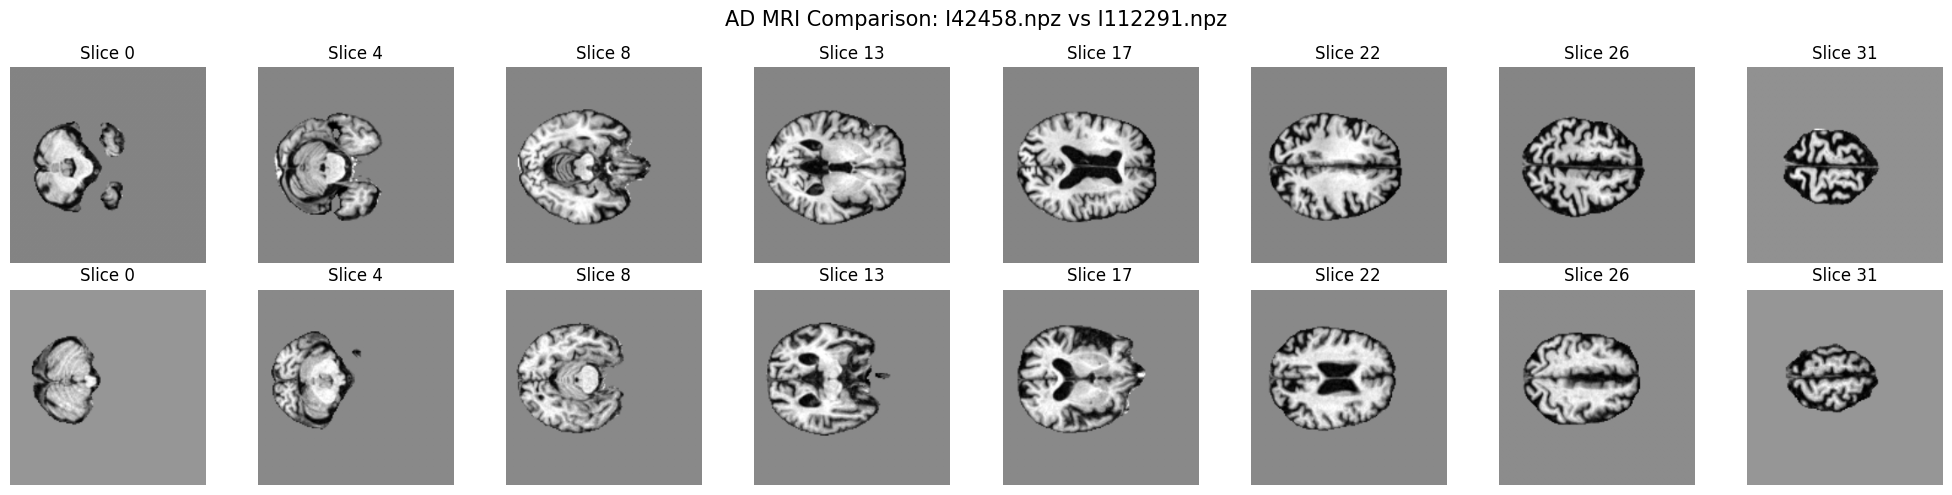

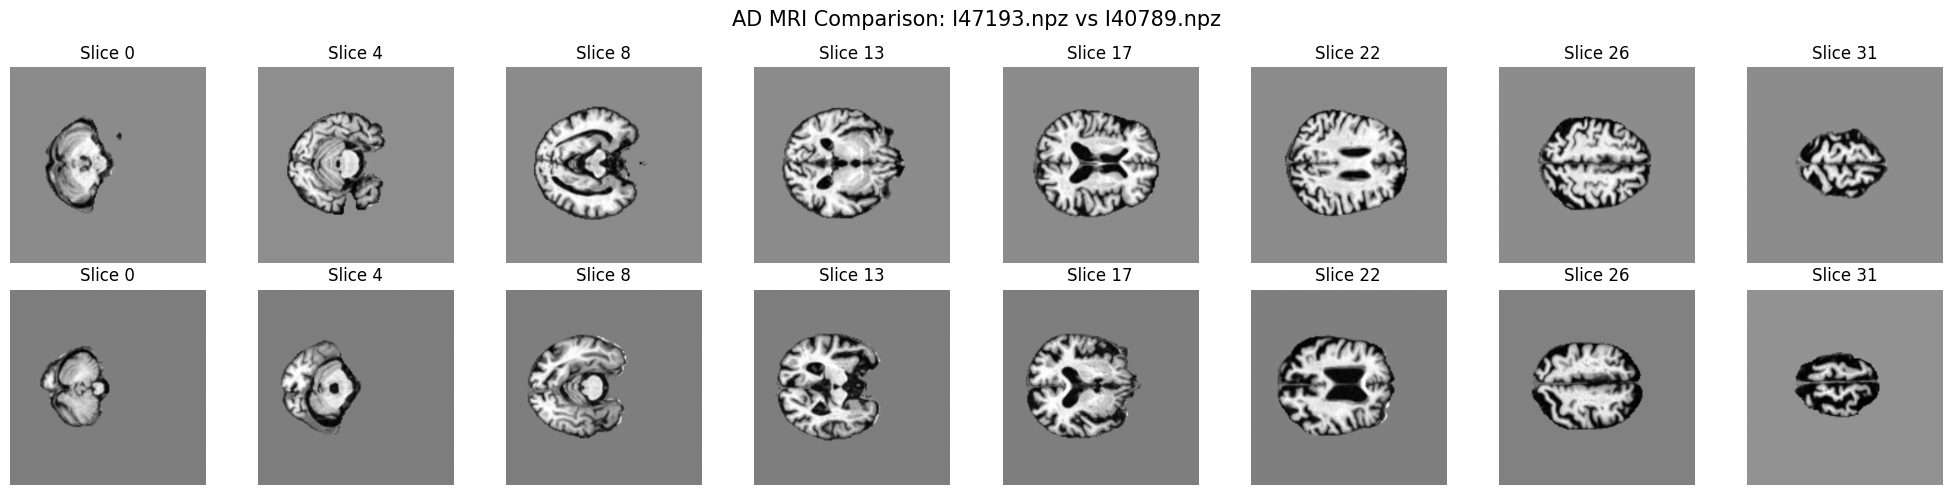

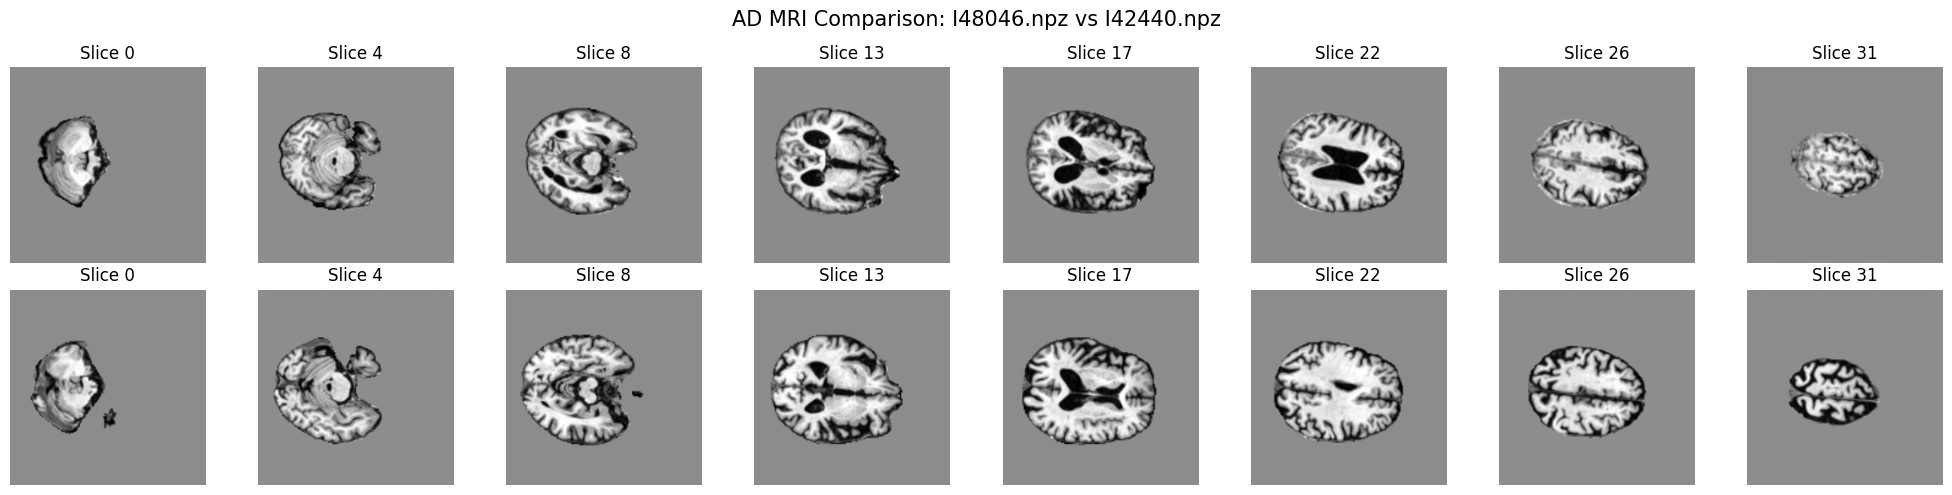

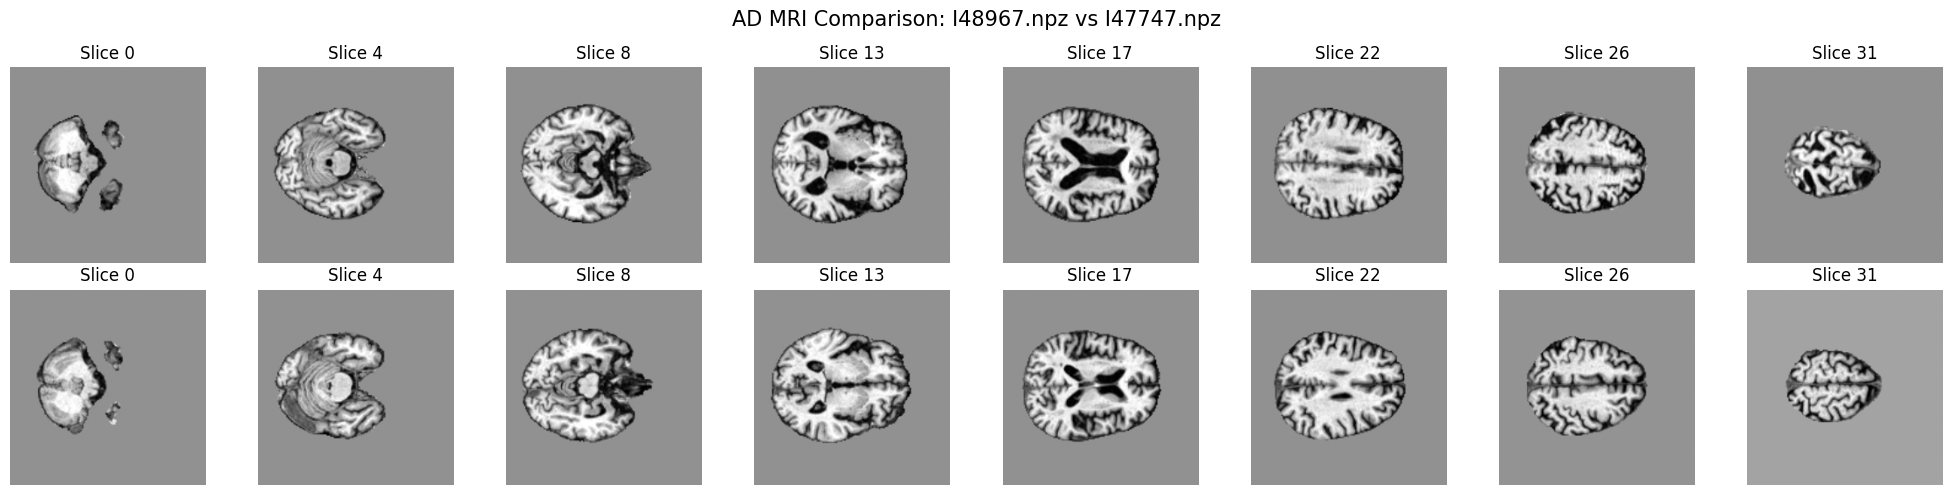

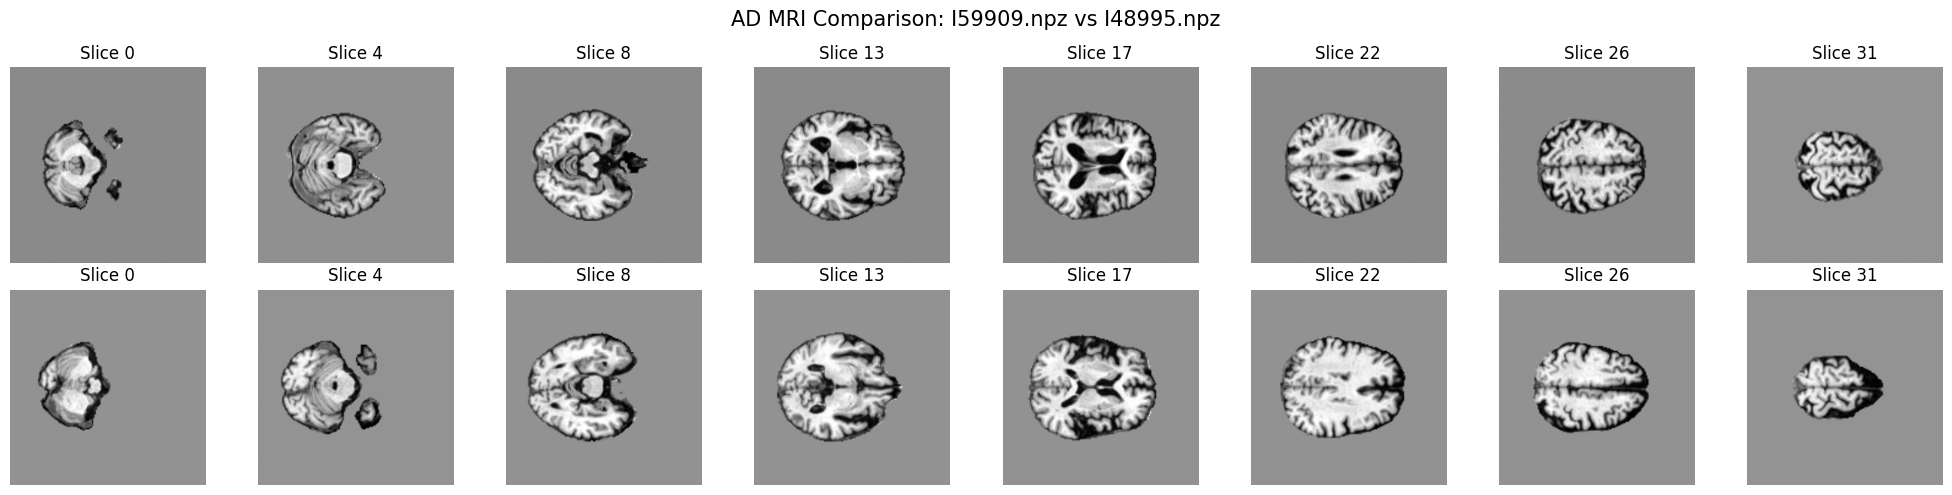

In [ ]:
# ============================================================
# CORRECT AD vs AD → MCI
# VISUAL COMPARISON
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

LOCAL_TEST_DIR = "/content/Alzheimer_Preprocessed/test"

correct_ad_files = [
    "I42458.npz",
    "I47193.npz",
    "I48046.npz",
    "I48967.npz",
    "I59909.npz"
]

misclassified_ad_files = [
    "I112291.npz",
    "I40789.npz",
    "I42440.npz",
    "I47747.npz",
    "I48995.npz"
]


def load_mri(filename):

    path = os.path.join(LOCAL_TEST_DIR, filename)

    data = np.load(path)

    if "data" in data:
        volume = data["data"]
    elif "images" in data:
        volume = data["images"]
    else:
        raise KeyError(f"No image array found in {filename}")

    return volume.astype(np.float32)


# Same slice locations for every MRI
slice_indices = [0, 4, 8, 13, 17, 22, 26, 31]


# ============================================================
# Display paired comparisons
# ============================================================

for correct_file, error_file in zip(
    correct_ad_files,
    misclassified_ad_files
):

    correct_volume = load_mri(correct_file)
    error_volume = load_mri(error_file)

    fig, axes = plt.subplots(
        2, 8,
        figsize=(20, 5)
    )

    for col, slice_idx in enumerate(slice_indices):

        # Correct AD
        img_correct = correct_volume[slice_idx, :, :, 1]

        axes[0, col].imshow(
            img_correct,
            cmap="gray"
        )
        axes[0, col].set_title(f"Slice {slice_idx}")
        axes[0, col].axis("off")

        # AD → MCI
        img_error = error_volume[slice_idx, :, :, 1]

        axes[1, col].imshow(
            img_error,
            cmap="gray"
        )
        axes[1, col].set_title(f"Slice {slice_idx}")
        axes[1, col].axis("off")

    axes[0, 0].set_ylabel(
        f"Correct AD\n{correct_file}",
        fontsize=11
    )

    axes[1, 0].set_ylabel(
        f"AD → MCI\n{error_file}",
        fontsize=11
    )

    fig.suptitle(
        f"AD MRI Comparison: {correct_file} vs {error_file}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# MEAN + MAX SLICE POOLING EXPERIMENT
# ============================================================

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

class MRIResNet18_MeanMax(nn.Module):

    def __init__(self, num_classes=3, num_slices=32):

        super().__init__()

        self.num_slices = num_slices

        self.backbone = models.resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )

        self.backbone.fc = nn.Identity()

        # 512 mean + 512 max = 1024
        self.classifier = nn.Sequential(
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        x = x.reshape(B * S, C, H, W)

        features = self.backbone(x)

        features = features.reshape(B, S, 512)

        # Mean pooling
        mean_features = features.mean(dim=1)

        # Max pooling
        max_features = features.max(dim=1).values

        # Combine
        pooled = torch.cat(
            [mean_features, max_features],
            dim=1
        )

        return self.classifier(pooled)


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

model_meanmax = MRIResNet18_MeanMax().to(device)

# ------------------------------------------------------------
# Freeze backbone
# ------------------------------------------------------------

for param in model_meanmax.backbone.parameters():
    param.requires_grad = False

for param in model_meanmax.classifier.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_meanmax.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_meanmax.parameters()
    if p.requires_grad
)

print("=" * 70)
print("MEAN + MAX POOLING MODEL")
print("=" * 70)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

MEAN + MAX POOLING MODEL
Total parameters:     11,439,683
Trainable parameters: 263,171
Frozen parameters:    11,176,512


In [ ]:
# ============================================================
# MEAN + MAX POOLING — TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

class_weights = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_mm = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Optimizer
# Only classifier is trainable
# ------------------------------------------------------------

optimizer_mm = optim.AdamW(
    model_meanmax.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_mm = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mm,
    mode="max",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def run_epoch_meanmax(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()

        # Keep frozen backbone in eval mode
        model.backbone.eval()

    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += loss.item() * labels.size(0)

        preds = torch.argmax(logits, dim=1)

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        epoch_loss,
        epoch_acc,
        epoch_f1,
        epoch_bal
    )


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

MM_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_meanmax.pth"
)

NUM_EPOCHS_MM = 5

best_val_f1_mm = -1.0
best_epoch_mm = 0

print("=" * 70)
print("MEAN + MAX POOLING TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_MM + 1):

    print(
        f"\n{'=' * 70}\n"
        f"MEAN + MAX — EPOCH {epoch}/{NUM_EPOCHS_MM}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_meanmax(
            model_meanmax,
            train_loader,
            criterion_mm,
            optimizer_mm
        )
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_meanmax(
            model_meanmax,
            val_loader,
            criterion_mm,
            optimizer=None
        )
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler_mm.step(val_f1)

    current_lr = optimizer_mm.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(f"Learning Rate: {current_lr:.2e}")

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_f1 > best_val_f1_mm:

        best_val_f1_mm = val_f1
        best_epoch_mm = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_meanmax.state_dict(),
                "optimizer_state_dict":
                    optimizer_mm.state_dict(),
                "scheduler_state_dict":
                    scheduler_mm.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            MM_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )

print("\n" + "=" * 70)
print("MEAN + MAX EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_mm}")
print(f"Best validation Macro-F1: {best_val_f1_mm:.4f}")

MEAN + MAX POOLING TRAINING

MEAN + MAX — EPOCH 1/5
Train Loss: 1.1958 | Train Acc: 0.3296 | Train F1: 0.3117 | Train Bal: 0.3147
Val Loss:   1.1178 | Val Acc:    0.2316 | Val F1:     0.1254 | Val Bal:    0.3333
Learning Rate: 1.00e-04
✓ Best model saved (Val F1 = 0.1254)

MEAN + MAX — EPOCH 2/5
Train Loss: 1.1271 | Train Acc: 0.3883 | Train F1: 0.3798 | Train Bal: 0.3904
Val Loss:   1.1220 | Val Acc:    0.4947 | Val F1:     0.2207 | Val Bal:    0.3333
Learning Rate: 1.00e-04
✓ Best model saved (Val F1 = 0.2207)

MEAN + MAX — EPOCH 3/5
Train Loss: 1.1329 | Train Acc: 0.3770 | Train F1: 0.3638 | Train Bal: 0.3722
Val Loss:   1.1151 | Val Acc:    0.2316 | Val F1:     0.1254 | Val Bal:    0.3333
Learning Rate: 1.00e-04

MEAN + MAX — EPOCH 4/5
Train Loss: 1.1110 | Train Acc: 0.3589 | Train F1: 0.3467 | Train Bal: 0.3527
Val Loss:   1.1186 | Val Acc:    0.4947 | Val F1:     0.2207 | Val Bal:    0.3333
Learning Rate: 1.00e-04

MEAN + MAX — EPOCH 5/5
Train Loss: 1.1107 | Train Acc: 0.3837 | T

In [ ]:
# ============================================================
# CHECK ORIGINAL BASELINE CHECKPOINT
# ============================================================

BEST_BASELINE_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

base_checkpoint = torch.load(
    BEST_BASELINE_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:")
print(list(base_checkpoint.keys()))

Checkpoint keys:
['backbone.conv1.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.bn1.running_mean', 'backbone.bn1.running_var', 'backbone.bn1.num_batches_tracked', 'backbone.layer1.0.conv1.weight', 'backbone.layer1.0.bn1.weight', 'backbone.layer1.0.bn1.bias', 'backbone.layer1.0.bn1.running_mean', 'backbone.layer1.0.bn1.running_var', 'backbone.layer1.0.bn1.num_batches_tracked', 'backbone.layer1.0.conv2.weight', 'backbone.layer1.0.bn2.weight', 'backbone.layer1.0.bn2.bias', 'backbone.layer1.0.bn2.running_mean', 'backbone.layer1.0.bn2.running_var', 'backbone.layer1.0.bn2.num_batches_tracked', 'backbone.layer1.1.conv1.weight', 'backbone.layer1.1.bn1.weight', 'backbone.layer1.1.bn1.bias', 'backbone.layer1.1.bn1.running_mean', 'backbone.layer1.1.bn1.running_var', 'backbone.layer1.1.bn1.num_batches_tracked', 'backbone.layer1.1.conv2.weight', 'backbone.layer1.1.bn2.weight', 'backbone.layer1.1.bn2.bias', 'backbone.layer1.1.bn2.running_mean', 'backbone.layer1.1.bn2.running_var', '

In [ ]:
# ============================================================
# MEAN + MAX — LOAD MRI-TRAINED BACKBONE CORRECTLY
# ============================================================

import torch

BEST_BASELINE_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

# ------------------------------------------------------------
# Load original checkpoint
# ------------------------------------------------------------

base_checkpoint = torch.load(
    BEST_BASELINE_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print("✓ Original checkpoint loaded")
print(f"Checkpoint contains {len(base_checkpoint)} tensors")


# ------------------------------------------------------------
# Create fresh Mean + Max model
# ------------------------------------------------------------

model_meanmax = MRIResNet18_MeanMax().to(device)


# ------------------------------------------------------------
# Extract ONLY backbone weights
# ------------------------------------------------------------

backbone_state = {
    key.replace("backbone.", "", 1): value
    for key, value in base_checkpoint.items()
    if key.startswith("backbone.")
}

print(f"Backbone tensors extracted: {len(backbone_state)}")


# ------------------------------------------------------------
# Load MRI-trained backbone
# ------------------------------------------------------------

missing_keys, unexpected_keys = (
    model_meanmax.backbone.load_state_dict(
        backbone_state,
        strict=True
    )
)

print("✓ MRI-trained ResNet18 backbone transferred")


# ------------------------------------------------------------
# Freeze backbone
# ------------------------------------------------------------

for param in model_meanmax.backbone.parameters():
    param.requires_grad = False

# Keep Mean + Max classifier trainable
for param in model_meanmax.classifier.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_meanmax.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_meanmax.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("MEAN + MAX — MRI-TRAINED BACKBONE")
print("=" * 70)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

✓ Original checkpoint loaded
Checkpoint contains 122 tensors
Backbone tensors extracted: 120
✓ MRI-trained ResNet18 backbone transferred

MEAN + MAX — MRI-TRAINED BACKBONE
Total parameters:     11,439,683
Trainable parameters: 263,171
Frozen parameters:    11,176,512


In [ ]:
# ============================================================
# MEAN + MAX — CORRECTED TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

class_weights_mm = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

criterion_mm = nn.CrossEntropyLoss(
    weight=class_weights_mm,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_mm = optim.AdamW(
    model_meanmax.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_mm = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mm,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_meanmax(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()

        # Backbone is frozen, keep it in eval mode
        model.backbone.eval()

    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    loss_value = (
        running_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        loss_value,
        accuracy,
        macro_f1,
        balanced_acc
    )


# ============================================================
# Training
# ============================================================

MM_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_meanmax_mritrained.pth"
)

NUM_EPOCHS_MM = 5

best_val_f1_mm = -1.0
best_epoch_mm = 0

print("=" * 70)
print("MEAN + MAX — MRI-TRAINED BACKBONE")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_MM + 1):

    print(
        f"\n{'=' * 70}\n"
        f"MEAN + MAX — EPOCH {epoch}/{NUM_EPOCHS_MM}\n"
        f"{'=' * 70}"
    )

    # -----------------------------
    # Train
    # -----------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_meanmax(
            model_meanmax,
            train_loader,
            criterion_mm,
            optimizer_mm
        )
    )

    # -----------------------------
    # Validation
    # -----------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_meanmax(
            model_meanmax,
            val_loader,
            criterion_mm,
            optimizer=None
        )
    )

    # -----------------------------
    # Scheduler
    # -----------------------------

    scheduler_mm.step(val_f1)

    lr = optimizer_mm.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(f"Learning Rate: {lr:.2e}")

    # -----------------------------
    # Save best
    # -----------------------------

    if val_f1 > best_val_f1_mm:

        best_val_f1_mm = val_f1
        best_epoch_mm = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_meanmax.state_dict(),
                "optimizer_state_dict":
                    optimizer_mm.state_dict(),
                "scheduler_state_dict":
                    scheduler_mm.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            MM_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )


print("\n" + "=" * 70)
print("CORRECTED MEAN + MAX EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_mm}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_mm:.4f}"
)

MEAN + MAX — MRI-TRAINED BACKBONE

MEAN + MAX — EPOCH 1/5
Train Loss: 1.0861 | Train Acc: 0.4199 | Train F1: 0.3960 | Train Bal: 0.4211
Val Loss:   1.0367 | Val Acc:    0.5053 | Val F1:     0.3660 | Val Bal:    0.3922
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3660)

MEAN + MAX — EPOCH 2/5
Train Loss: 0.9560 | Train Acc: 0.5214 | Train F1: 0.5180 | Train Bal: 0.5333
Val Loss:   1.0000 | Val Acc:    0.5263 | Val F1:     0.4622 | Val Bal:    0.4522
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.4622)

MEAN + MAX — EPOCH 3/5
Train Loss: 0.8937 | Train Acc: 0.5779 | Train F1: 0.5768 | Train Bal: 0.6025
Val Loss:   1.0396 | Val Acc:    0.5263 | Val F1:     0.4576 | Val Bal:    0.4556
Learning Rate: 1.00e-05

MEAN + MAX — EPOCH 4/5
Train Loss: 0.8628 | Train Acc: 0.6185 | Train F1: 0.6120 | Train Bal: 0.6337
Val Loss:   1.1061 | Val Acc:    0.5053 | Val F1:     0.4115 | Val Bal:    0.4253
Learning Rate: 1.00e-05

MEAN + MAX — EPOCH 5/5
Train Loss: 0.8349 | Train Acc: 0.64

✓ MRI-trained ResNet18 loaded

Train features:
(443, 512)
(443,)

Validation features:
(95, 512)
(95,)

PCA explained variance:
PC1: 0.4785
PC2: 0.4157
Total: 0.8942


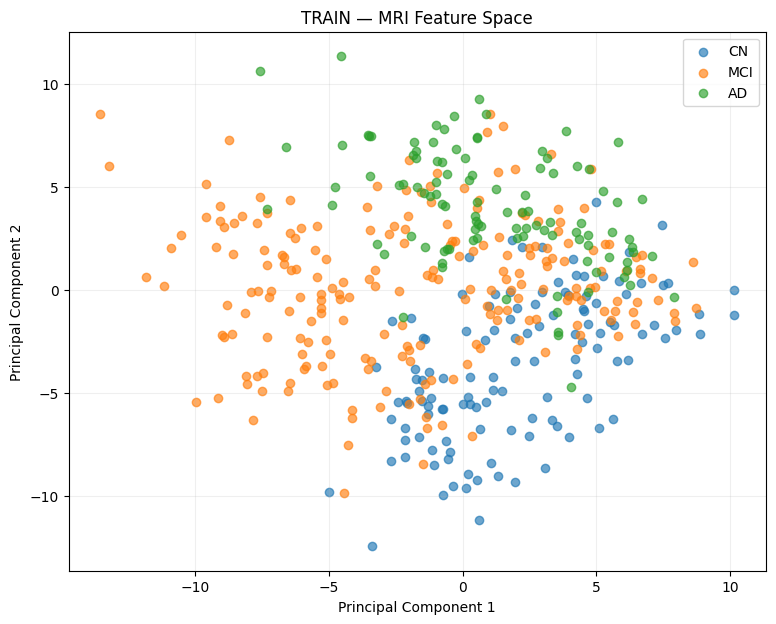

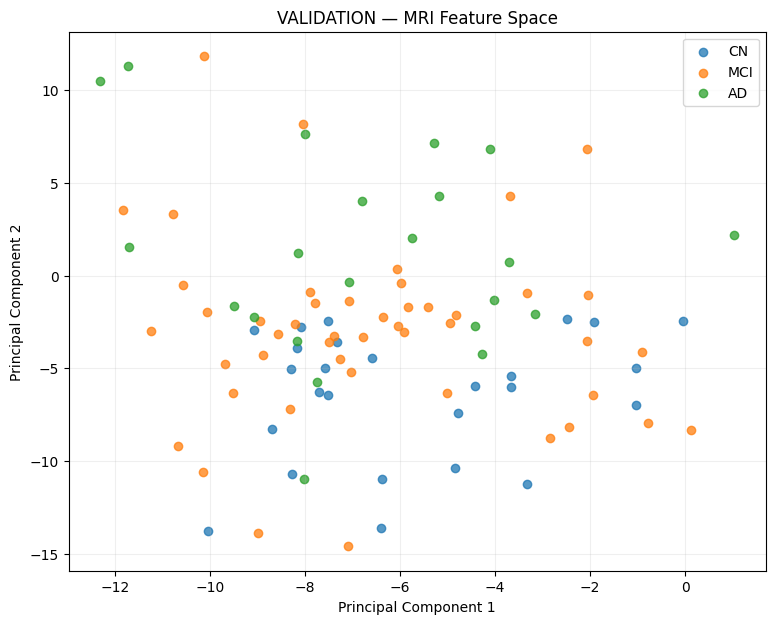


✓ Feature-space analysis complete


In [ ]:
# ============================================================
# FEATURE-SPACE ANALYSIS
# MRI-TRAINED RESNET18 → 512-D FEATURES → PCA
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. Load the original MRI-trained best model
# ------------------------------------------------------------

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

analysis_model = MRIResNet18_32Slice().to(device)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Original checkpoint is a raw state_dict
analysis_model.load_state_dict(
    checkpoint,
    strict=True
)

analysis_model.eval()

# We only need the ResNet backbone
backbone = analysis_model.backbone
backbone.eval()

print("✓ MRI-trained ResNet18 loaded")


# ------------------------------------------------------------
# 2. Feature extraction function
# ------------------------------------------------------------

def extract_mean_features(loader):

    features_all = []
    labels_all = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            B, S, C, H, W = images.shape

            # [B, S, C, H, W]
            #       ↓
            # [B*S, C, H, W]

            x = images.reshape(
                B * S,
                C,
                H,
                W
            )

            # ResNet feature extraction
            features = backbone(x)

            # [B*S, 512]
            features = features.reshape(
                B,
                S,
                512
            )

            # Same mean pooling used by
            # the successful baseline model
            mean_features = features.mean(dim=1)

            features_all.append(
                mean_features.cpu().numpy()
            )

            labels_all.append(
                labels.numpy()
            )

    return (
        np.concatenate(features_all, axis=0),
        np.concatenate(labels_all, axis=0)
    )


# ------------------------------------------------------------
# 3. Extract TRAIN features
# ------------------------------------------------------------

train_features, train_labels = extract_mean_features(
    train_loader
)

print("\nTrain features:")
print(train_features.shape)
print(train_labels.shape)


# ------------------------------------------------------------
# 4. Extract VALIDATION features
# ------------------------------------------------------------

val_features, val_labels = extract_mean_features(
    val_loader
)

print("\nValidation features:")
print(val_features.shape)
print(val_labels.shape)


# ------------------------------------------------------------
# 5. Fit PCA ONLY on training features
# ------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

train_pca = pca.fit_transform(
    train_features
)

val_pca = pca.transform(
    val_features
)

print("\nPCA explained variance:")
print(
    f"PC1: {pca.explained_variance_ratio_[0]:.4f}"
)

print(
    f"PC2: {pca.explained_variance_ratio_[1]:.4f}"
)

print(
    f"Total: "
    f"{pca.explained_variance_ratio_.sum():.4f}"
)


# ------------------------------------------------------------
# 6. Plot TRAIN feature space
# ------------------------------------------------------------

class_names = ["CN", "MCI", "AD"]

plt.figure(figsize=(9, 7))

for class_id, class_name in enumerate(class_names):

    mask = train_labels == class_id

    plt.scatter(
        train_pca[mask, 0],
        train_pca[mask, 1],
        label=class_name,
        alpha=0.65
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("TRAIN — MRI Feature Space")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# ------------------------------------------------------------
# 7. Plot VALIDATION feature space
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for class_id, class_name in enumerate(class_names):

    mask = val_labels == class_id

    plt.scatter(
        val_pca[mask, 0],
        val_pca[mask, 1],
        label=class_name,
        alpha=0.75
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("VALIDATION — MRI Feature Space")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\n✓ Feature-space analysis complete")

In [ ]:
# ============================================================
# MRI-TRAINED RESNET18 + LIGHTWEIGHT SLICE ATTENTION
# ============================================================

import torch
import torch.nn as nn


class MRIResNet18_LightAttention(nn.Module):

    def __init__(self, num_classes=3, num_slices=32):

        super().__init__()

        self.num_slices = num_slices

        # ----------------------------------------------------
        # ResNet18 backbone
        # ----------------------------------------------------

        self.backbone = MRIResNet18_32Slice().backbone

        # ----------------------------------------------------
        # Lightweight attention network
        # 512 -> 128 -> 1 score for each slice
        # ----------------------------------------------------

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # ----------------------------------------------------
        # Final classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(
            nn.Dropout(0.30),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        # ----------------------------------------------------
        # Process every slice independently
        # ----------------------------------------------------

        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        # [B*S, 512]
        features = features.reshape(
            B,
            S,
            512
        )

        # ----------------------------------------------------
        # Attention scores
        # ----------------------------------------------------

        attention_scores = self.attention(features)

        # [B, S, 1]
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # ----------------------------------------------------
        # Weighted slice aggregation
        # ----------------------------------------------------

        pooled_features = (
            features * attention_weights
        ).sum(dim=1)

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(
            pooled_features
        )

        return logits


# ============================================================
# Create model
# ============================================================

model_attn = MRIResNet18_LightAttention().to(device)

print("=" * 70)
print("LIGHTWEIGHT ATTENTION MODEL")
print("=" * 70)

print(
    f"Total parameters: "
    f"{sum(p.numel() for p in model_attn.parameters()):,}"
)

LIGHTWEIGHT ATTENTION MODEL
Total parameters: 11,243,844


In [ ]:
# ============================================================
# LOAD MRI-TRAINED BACKBONE
# ============================================================

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Extract backbone tensors
backbone_state = {
    key.replace("backbone.", "", 1): value
    for key, value in checkpoint.items()
    if key.startswith("backbone.")
}

# Load them
model_attn.backbone.load_state_dict(
    backbone_state,
    strict=True
)

print("✓ MRI-trained ResNet18 backbone loaded")


# ============================================================
# Freeze backbone
# ============================================================

for param in model_attn.backbone.parameters():
    param.requires_grad = False


# Attention + classifier remain trainable
for param in model_attn.attention.parameters():
    param.requires_grad = True

for param in model_attn.classifier.parameters():
    param.requires_grad = True


# ============================================================
# Parameter counts
# ============================================================

total_params = sum(
    p.numel()
    for p in model_attn.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_attn.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("PARAMETERS")
print("=" * 70)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

✓ MRI-trained ResNet18 backbone loaded

PARAMETERS
Total parameters:     11,243,844
Trainable parameters: 67,332
Frozen parameters:    11,176,512


In [ ]:
# ============================================================
# LIGHTWEIGHT ATTENTION — TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

class_weights_attn = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_attn = nn.CrossEntropyLoss(
    weight=class_weights_attn,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Optimizer
# Train ONLY attention + classifier
# ------------------------------------------------------------

trainable_params_attn = [
    p for p in model_attn.parameters()
    if p.requires_grad
]

optimizer_attn = optim.AdamW(
    trainable_params_attn,
    lr=1e-5,
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_attn = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_attn,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_attention(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()

        # Backbone is frozen.
        # Keep it in eval mode so BatchNorm statistics
        # don't change.
        model.backbone.eval()

    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    trainable_params_attn,
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        epoch_loss,
        epoch_acc,
        epoch_f1,
        epoch_bal
    )


# ============================================================
# Training loop
# ============================================================

ATTN_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_light_attention.pth"
)

NUM_EPOCHS_ATTN = 5

best_val_f1_attn = -1.0
best_epoch_attn = 0

print("=" * 70)
print("LIGHTWEIGHT ATTENTION — MRI-TRAINED BACKBONE")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_ATTN + 1):

    print(
        f"\n{'=' * 70}\n"
        f"ATTENTION — EPOCH {epoch}/{NUM_EPOCHS_ATTN}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_attention(
            model_attn,
            train_loader,
            criterion_attn,
            optimizer_attn
        )
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_attention(
            model_attn,
            val_loader,
            criterion_attn,
            optimizer=None
        )
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler_attn.step(val_f1)

    current_lr = optimizer_attn.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(f"Learning Rate: {current_lr:.2e}")

    # --------------------------------------------------------
    # Save best
    # --------------------------------------------------------

    if val_f1 > best_val_f1_attn:

        best_val_f1_attn = val_f1
        best_epoch_attn = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_attn.state_dict(),
                "optimizer_state_dict":
                    optimizer_attn.state_dict(),
                "scheduler_state_dict":
                    scheduler_attn.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            ATTN_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )


print("\n" + "=" * 70)
print("LIGHTWEIGHT ATTENTION EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_attn}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_attn:.4f}"
)

LIGHTWEIGHT ATTENTION — MRI-TRAINED BACKBONE

ATTENTION — EPOCH 1/5
Train Loss: 1.1368 | Train Acc: 0.3928 | Train F1: 0.3359 | Train Bal: 0.3842
Val Loss:   1.0995 | Val Acc:    0.4105 | Val F1:     0.3037 | Val Bal:    0.4198
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3037)

ATTENTION — EPOCH 2/5
Train Loss: 1.0933 | Train Acc: 0.4289 | Train F1: 0.3819 | Train Bal: 0.4126
Val Loss:   1.0788 | Val Acc:    0.4632 | Val F1:     0.3510 | Val Bal:    0.4209
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3510)

ATTENTION — EPOCH 3/5
Train Loss: 1.0737 | Train Acc: 0.4695 | Train F1: 0.4292 | Train Bal: 0.4481
Val Loss:   1.0588 | Val Acc:    0.4842 | Val F1:     0.3640 | Val Bal:    0.4236
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3640)

ATTENTION — EPOCH 4/5
Train Loss: 1.0303 | Train Acc: 0.5214 | Train F1: 0.4854 | Train Bal: 0.5005
Val Loss:   1.0443 | Val Acc:    0.5368 | Val F1:     0.3988 | Val Bal:    0.4534
Learning Rate: 1.00e-05
✓ Best model sav

In [ ]:
# ============================================================
# TRAIN / VALIDATION / TEST DEMOGRAPHIC DISTRIBUTION
# ============================================================

import pandas as pd
import numpy as np

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(METADATA_PATH)

print("=" * 80)
print("CLASS DISTRIBUTION BY SPLIT")
print("=" * 80)

class_split = pd.crosstab(
    metadata["Split"],
    metadata["Group"],
    normalize="index"
) * 100

display(class_split.round(2))


# ============================================================
# AGE DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("AGE DISTRIBUTION BY SPLIT")
print("=" * 80)

age_stats = (
    metadata
    .groupby("Split")["Age"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(age_stats.round(2))


# ============================================================
# AGE BY CLASS AND SPLIT
# ============================================================

print("\n" + "=" * 80)
print("AGE BY CLASS AND SPLIT")
print("=" * 80)

age_class_stats = (
    metadata
    .groupby(["Split", "Group"])["Age"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(age_class_stats.round(2))


# ============================================================
# SEX DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("SEX DISTRIBUTION BY SPLIT")
print("=" * 80)

sex_split = pd.crosstab(
    metadata["Split"],
    metadata["Sex"],
    normalize="index"
) * 100

display(sex_split.round(2))


# ============================================================
# SUBJECT COUNTS
# ============================================================

print("\n" + "=" * 80)
print("SUBJECT COUNTS")
print("=" * 80)

subject_counts = (
    metadata.groupby("Split")["Subject"]
    .nunique()
)

display(subject_counts)


print("\n✓ Distribution analysis complete")

CLASS DISTRIBUTION BY SPLIT


Group,AD,CN,MCI
Split,,,
test,22.83,28.26,48.91
train,23.93,27.54,48.53
validation,23.16,27.37,49.47



AGE DISTRIBUTION BY SPLIT


,count,mean,std,min,median,max
Split,,,,,,
test,92,75.30,6.67,55,76.0,88
train,443,75.71,6.90,55,76.0,91
validation,95,74.68,7.34,56,75.0,88



AGE BY CLASS AND SPLIT


count   mean   std  min  median  max
Split      Group                                      
test       AD        21  74.67  9.16   55    77.0   87
           CN        26  76.85  4.90   71    76.0   88
           MCI       45  74.71  6.19   57    76.0   85
train      AD       106  76.36  7.23   57    77.0   91
           CN       122  76.30  5.31   60    76.0   90
           MCI      215  75.07  7.48   55    75.0   90
validation AD        22  75.00  7.26   56    75.0   87
           CN        26  76.00  5.90   63    76.5   85
           MCI       47  73.81  8.09   56    74.0   88


SEX DISTRIBUTION BY SPLIT


Sex,F,M
Split,,
test,43.48,56.52
train,47.18,52.82
validation,37.89,62.11



SUBJECT COUNTS


,Subject
Split,
test,92
train,427
validation,91



✓ Distribution analysis complete


In [ ]:
# ============================================================
# SUBJECT REPEATS + ACQUISITION DESCRIPTION ANALYSIS
# ============================================================

import pandas as pd

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(METADATA_PATH)

# ------------------------------------------------------------
# 1. Number of MRI images per subject
# ------------------------------------------------------------

subject_counts = (
    metadata
    .groupby(["Split", "Subject"])
    .size()
    .reset_index(name="MRI_count")
)

print("=" * 80)
print("SUBJECTS WITH MULTIPLE MRIs")
print("=" * 80)

multiple = subject_counts[
    subject_counts["MRI_count"] > 1
]

display(multiple.sort_values(
    ["Split", "MRI_count"],
    ascending=[True, False]
))

print(
    f"\nSubjects with >1 MRI: {len(multiple)}"
)


# ------------------------------------------------------------
# 2. Number of images per class for repeated subjects
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REPEATED MRI COUNTS BY CLASS")
print("=" * 80)

repeated_subjects = multiple["Subject"].tolist()

repeated_df = metadata[
    metadata["Subject"].isin(repeated_subjects)
].copy()

display(
    repeated_df.groupby(
        ["Split", "Group"]
    ).size().unstack(fill_value=0)
)


# ------------------------------------------------------------
# 3. Description distribution
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DESCRIPTION VALUES")
print("=" * 80)

print(
    "Unique descriptions:",
    metadata["Description"].nunique()
)

display(
    metadata["Description"]
    .value_counts(dropna=False)
)


# ------------------------------------------------------------
# 4. Description by split
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DESCRIPTION × SPLIT")
print("=" * 80)

description_split = pd.crosstab(
    metadata["Description"],
    metadata["Split"]
)

display(description_split)


# ------------------------------------------------------------
# 5. Description by class
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DESCRIPTION × CLASS")
print("=" * 80)

description_class = pd.crosstab(
    metadata["Description"],
    metadata["Group"]
)

display(description_class)


# ------------------------------------------------------------
# 6. Visit distribution
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("VISIT DISTRIBUTION")
print("=" * 80)

print(
    metadata["Visit"].value_counts(dropna=False)
)

print("\nVisit × Split:")
display(
    pd.crosstab(
        metadata["Visit"],
        metadata["Split"]
    )
)

print("\n✓ Acquisition/repeat analysis complete")

SUBJECTS WITH MULTIPLE MRIs


,Split,Subject,MRI_count
111,train,003_S_1122,2
118,train,005_S_0572,2
125,train,006_S_0498,2
126,train,006_S_0547,2
127,train,006_S_0653,2
162,train,013_S_1275,2
183,train,020_S_0883,2
282,train,035_S_0555,2
293,train,036_S_1001,2
300,train,041_S_0446,2



Subjects with >1 MRI: 19

REPEATED MRI COUNTS BY CLASS


Group,AD,CN,MCI
Split,,,
train,8,8,16
validation,0,2,5



DESCRIPTION VALUES
Unique descriptions: 1


,count
Description,
MPR; GradWarp; B1 Correction; N3,630


... (3 outputs left out)

Group,AD,CN,MCI
Description,,,
MPR; GradWarp; B1 Correction; N3,149,174,307



VISIT DISTRIBUTION
Visit
sc    630
Name: count, dtype: int64

Visit × Split:


Split,test,train,validation
Visit,,,
sc,92,443,95



✓ Acquisition/repeat analysis complete


In [ ]:
# ============================================================
# INSPECT REPEATED SUBJECTS
# ============================================================

import pandas as pd

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(METADATA_PATH)

# ------------------------------------------------------------
# Find subjects with multiple MRI samples
# ------------------------------------------------------------

subject_counts = (
    metadata
    .groupby(["Split", "Subject"])
    .size()
    .reset_index(name="MRI_count")
)

repeated_subjects = subject_counts[
    subject_counts["MRI_count"] > 1
][["Split", "Subject", "MRI_count"]]


# ------------------------------------------------------------
# Show every MRI belonging to repeated subjects
# ------------------------------------------------------------

repeated_details = metadata.merge(
    repeated_subjects,
    on=["Split", "Subject"],
    how="inner"
)

columns_to_show = [
    "Split",
    "Subject",
    "Group",
    "Image Data ID",
    "MRI_File_Name",
    "Acq Date",
    "Description",
    "Visit",
    "MRI_count"
]

print("=" * 100)
print("REPEATED SUBJECT MRI DETAILS")
print("=" * 100)

display(
    repeated_details[
        columns_to_show
    ].sort_values(
        ["Split", "Subject", "MRI_File_Name"]
    )
)


# ------------------------------------------------------------
# Check whether labels differ within the same subject
# ------------------------------------------------------------

label_consistency = (
    repeated_details
    .groupby(["Split", "Subject"])["Group"]
    .nunique()
)

print("\n" + "=" * 100)
print("LABEL CONSISTENCY")
print("=" * 100)

print(
    "Subjects with different labels across their MRI samples:",
    (label_consistency > 1).sum()
)

print(
    "Subjects with consistent labels:",
    (label_consistency == 1).sum()
)


# ------------------------------------------------------------
# Check acquisition dates
# ------------------------------------------------------------

date_counts = (
    repeated_details
    .groupby(["Split", "Subject"])["Acq Date"]
    .nunique()
)

print("\n" + "=" * 100)
print("ACQUISITION DATE CHECK")
print("=" * 100)

print(
    "Repeated subjects with multiple acquisition dates:",
    (date_counts > 1).sum()
)

display(
    repeated_details[
        ["Split", "Subject", "Group", "MRI_File_Name", "Acq Date"]
    ].sort_values(
        ["Split", "Subject", "MRI_File_Name"]
    )
)

REPEATED SUBJECT MRI DETAILS


,Split,Subject,Group,Image Data ID,MRI_File_Name,Acq Date,Description,Visit,MRI_count
37,train,003_S_1122,MCI,I52798,ADNI_003_S_1122_MR_MPR__GradWarp__B1_Correctio...,12/06/2006,MPR; GradWarp; B1 Correction; N3,sc,2
38,train,003_S_1122,MCI,I52803,ADNI_003_S_1122_MR_MPR__GradWarp__B1_Correctio...,12/06/2006,MPR; GradWarp; B1 Correction; N3,sc,2
35,train,005_S_0572,MCI,I32654,ADNI_005_S_0572_MR_MPR__GradWarp__B1_Correctio...,6/20/2006,MPR; GradWarp; B1 Correction; N3,sc,2
36,train,005_S_0572,MCI,I32663,ADNI_005_S_0572_MR_MPR__GradWarp__B1_Correctio...,6/20/2006,MPR; GradWarp; B1 Correction; N3,sc,2
33,train,006_S_0498,CN,I55938,ADNI_006_S_0498_MR_MPR__GradWarp__B1_Correctio...,9/19/2006,MPR; GradWarp; B1 Correction; N3,sc,2
34,train,006_S_0498,CN,I67056,ADNI_006_S_0498_MR_MPR__GradWarp__B1_Correctio...,6/26/2006,MPR; GradWarp; B1 Correction; N3,sc,2
31,train,006_S_0547,AD,I67314,ADNI_006_S_0547_MR_MPR__GradWarp__B1_Correctio...,6/29/2006,MPR; GradWarp; B1 Correction; N3,sc,2
32,train,006_S_0547,AD,I75270,ADNI_006_S_0547_MR_MPR__GradWarp__B1_Correctio...,9/21/2006,MPR; GradWarp; B1 Correction; N3,sc,2
29,train,006_S_0653,AD,I55947,ADNI_006_S_0653_MR_MPR__GradWarp__B1_Correctio...,11/14/2006,MPR; GradWarp; B1 Correction; N3,sc,2
30,train,006_S_0653,AD,I67323,ADNI_006_S_0653_MR_MPR__GradWarp__B1_Correctio...,7/05/2006,MPR; GradWarp; B1 Correction; N3,sc,2



LABEL CONSISTENCY
Subjects with different labels across their MRI samples: 0
Subjects with consistent labels: 19

ACQUISITION DATE CHECK
Repeated subjects with multiple acquisition dates: 8


,Split,Subject,Group,MRI_File_Name,Acq Date
37,train,003_S_1122,MCI,ADNI_003_S_1122_MR_MPR__GradWarp__B1_Correctio...,12/06/2006
38,train,003_S_1122,MCI,ADNI_003_S_1122_MR_MPR__GradWarp__B1_Correctio...,12/06/2006
35,train,005_S_0572,MCI,ADNI_005_S_0572_MR_MPR__GradWarp__B1_Correctio...,6/20/2006
36,train,005_S_0572,MCI,ADNI_005_S_0572_MR_MPR__GradWarp__B1_Correctio...,6/20/2006
33,train,006_S_0498,CN,ADNI_006_S_0498_MR_MPR__GradWarp__B1_Correctio...,9/19/2006
34,train,006_S_0498,CN,ADNI_006_S_0498_MR_MPR__GradWarp__B1_Correctio...,6/26/2006
31,train,006_S_0547,AD,ADNI_006_S_0547_MR_MPR__GradWarp__B1_Correctio...,6/29/2006
32,train,006_S_0547,AD,ADNI_006_S_0547_MR_MPR__GradWarp__B1_Correctio...,9/21/2006
29,train,006_S_0653,AD,ADNI_006_S_0653_MR_MPR__GradWarp__B1_Correctio...,11/14/2006
30,train,006_S_0653,AD,ADNI_006_S_0653_MR_MPR__GradWarp__B1_Correctio...,7/05/2006


In [ ]:
# ============================================================
# REPEATED MRI SIMILARITY ANALYSIS — CORRECTED
# ============================================================

import os
import numpy as np
import pandas as pd

METADATA_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"
LOCAL_ROOT = "/content/Alzheimer_Preprocessed"

metadata = pd.read_csv(METADATA_PATH)

# ------------------------------------------------------------
# Find repeated subjects
# ------------------------------------------------------------

subject_counts = (
    metadata
    .groupby(["Split", "Subject"])
    .size()
    .reset_index(name="count")
)

repeated = subject_counts[
    subject_counts["count"] > 1
]

rep = metadata.merge(
    repeated[["Split", "Subject"]],
    on=["Split", "Subject"],
    how="inner"
)

print("=" * 80)
print("REPEATED MRI SIMILARITY ANALYSIS")
print("=" * 80)

print(f"Repeated subjects: {len(repeated)}")


# ------------------------------------------------------------
# Correct mapping:
# Image Data ID -> Ixxxxx.npz
# ------------------------------------------------------------

def get_npz_path(image_data_id, split):

    # Convert to clean string
    image_id = str(image_data_id).strip()

    # Handle cases where pandas reads IDs as numbers
    if image_id.endswith(".0"):
        image_id = image_id[:-2]

    # Add I prefix if needed
    if not image_id.startswith("I"):
        image_id = "I" + image_id

    filename = image_id + ".npz"

    path = os.path.join(
        LOCAL_ROOT,
        split,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Preprocessed NPZ not found:\n{path}\n"
            f"Image Data ID = {image_data_id}"
        )

    return path


# ------------------------------------------------------------
# Load NPZ
# ------------------------------------------------------------

def load_npz(image_data_id, split):

    path = get_npz_path(
        image_data_id,
        split
    )

    data = np.load(path)

    if "data" in data:
        arr = data["data"]

    elif "images" in data:
        arr = data["images"]

    else:
        raise KeyError(
            f"No 'data' or 'images' key in {path}"
        )

    return arr.astype(np.float32)


# ------------------------------------------------------------
# Pairwise similarity
# ------------------------------------------------------------

results = []

for (split, subject), group in rep.groupby(
    ["Split", "Subject"]
):

    rows = group.reset_index(drop=True)

    for i in range(len(rows)):

        for j in range(i + 1, len(rows)):

            id1 = rows.loc[i, "Image Data ID"]
            id2 = rows.loc[j, "Image Data ID"]

            a = load_npz(id1, split)
            b = load_npz(id2, split)

            same_shape = a.shape == b.shape

            if not same_shape:

                results.append({
                    "Split": split,
                    "Subject": subject,
                    "Image_ID_1": id1,
                    "Image_ID_2": id2,
                    "Same_Date":
                        rows.loc[i, "Acq Date"]
                        == rows.loc[j, "Acq Date"],
                    "Shape": f"{a.shape} vs {b.shape}",
                    "Exact_Match": False,
                    "MAE": np.nan,
                    "Correlation": np.nan
                })

                continue

            # Absolute difference
            mae = np.mean(
                np.abs(a - b)
            )

            # Exact equality
            exact_match = np.array_equal(
                a,
                b
            )

            # Flatten
            x = a.reshape(-1)
            y = b.reshape(-1)

            correlation = np.corrcoef(
                x,
                y
            )[0, 1]

            results.append({
                "Split": split,
                "Subject": subject,
                "Image_ID_1": id1,
                "Image_ID_2": id2,
                "Same_Date":
                    rows.loc[i, "Acq Date"]
                    == rows.loc[j, "Acq Date"],
                "Shape": str(a.shape),
                "Exact_Match": exact_match,
                "MAE": mae,
                "Correlation": correlation
            })


results_df = pd.DataFrame(results)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PAIRWISE COMPARISON")
print("=" * 80)

display(
    results_df.sort_values(
        ["Split", "Subject"]
    )
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)

print(
    f"Total repeated pairs: "
    f"{len(results_df)}"
)

print(
    f"Exact duplicate pairs: "
    f"{results_df['Exact_Match'].sum()}"
)

print(
    f"Same-date pairs: "
    f"{results_df['Same_Date'].sum()}"
)


# ------------------------------------------------------------
# Correlation summary
# ------------------------------------------------------------

print("\nCorrelation by same acquisition date:")

corr_summary = (
    results_df
    .groupby("Same_Date")["Correlation"]
    .agg(
        ["count", "mean", "min", "max"]
    )
)

display(
    corr_summary.round(4)
)


# ------------------------------------------------------------
# MAE summary
# ------------------------------------------------------------

print("\nMAE by same acquisition date:")

mae_summary = (
    results_df
    .groupby("Same_Date")["MAE"]
    .agg(
        ["count", "mean", "min", "max"]
    )
)

display(
    mae_summary.round(6)
)

print("\n✓ Repeated MRI similarity analysis complete")

REPEATED MRI SIMILARITY ANALYSIS
Repeated subjects: 19

PAIRWISE COMPARISON


,Split,Subject,Image_ID_1,Image_ID_2,Same_Date,Shape,Exact_Match,MAE,Correlation
0,train,003_S_1122,I52798,I52803,True,"(32, 224, 224, 3)",False,0.101404,0.761900
1,train,005_S_0572,I32654,I32663,True,"(32, 224, 224, 3)",False,0.040513,0.958547
2,train,006_S_0498,I55938,I67056,False,"(32, 224, 224, 3)",False,0.241028,0.290047
3,train,006_S_0547,I67314,I75270,False,"(32, 224, 224, 3)",False,0.254532,0.113355
4,train,006_S_0653,I55947,I67323,False,"(32, 224, 224, 3)",False,0.135374,0.645268
5,train,013_S_1275,I62665,I62670,True,"(32, 224, 224, 3)",False,0.078896,0.883123
6,train,020_S_0883,I60672,I60677,True,"(32, 224, 224, 3)",False,0.089632,0.852512
7,train,035_S_0555,I39600,I39609,False,"(32, 224, 224, 3)",False,0.221242,0.408491
8,train,036_S_1001,I38660,I38665,True,"(32, 224, 224, 3)",False,0.117389,0.713335
9,train,041_S_0446,I40171,I40429,True,"(32, 224, 224, 3)",False,0.057730,0.941303



SUMMARY
Total repeated pairs: 21
Exact duplicate pairs: 0
Same-date pairs: 13

Correlation by same acquisition date:


,count,mean,min,max
Same_Date,,,,
False,8,0.4363,0.1134,0.7766
True,13,0.6934,0.2440,0.9792



MAE by same acquisition date:


,count,mean,min,max
Same_Date,,,,
False,8,0.188673,0.107409,0.254532
True,13,0.120564,0.033153,0.227711



✓ Repeated MRI similarity analysis complete


In [ ]:
# ============================================================
# SUBJECT-BALANCED TRAINING SAMPLER
# ============================================================

import torch
from torch.utils.data import WeightedRandomSampler, DataLoader
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

METADATA_PATH = (
    "/content/drive/MyDrive/metadata_subjectwise_split.csv"
)

metadata = pd.read_csv(METADATA_PATH)

train_metadata = metadata[
    metadata["Split"] == "train"
].copy()


# ------------------------------------------------------------
# Map dataset file -> Subject
# ------------------------------------------------------------

def get_image_id_from_path(path):

    filename = str(path).split("/")[-1]

    # I12345.npz -> I12345
    return filename.replace(".npz", "")


file_to_subject = {}

for _, row in train_metadata.iterrows():

    image_id = str(row["Image Data ID"])

    if not image_id.startswith("I"):
        image_id = "I" + image_id

    file_to_subject[image_id] = str(
        row["Subject"]
    )


# ------------------------------------------------------------
# Verify ordering against train_dataset
# ------------------------------------------------------------

subjects = []

for path in train_dataset.files:

    image_id = get_image_id_from_path(path)

    if image_id not in file_to_subject:

        raise KeyError(
            f"{image_id} not found in metadata"
        )

    subjects.append(
        file_to_subject[image_id]
    )


# ------------------------------------------------------------
# Calculate subject-balanced weights
# ------------------------------------------------------------

subject_counts = pd.Series(subjects).value_counts()

sample_weights = np.array([
    1.0 / subject_counts[s]
    for s in subjects
], dtype=np.float64)


# ------------------------------------------------------------
# Create sampler
# ------------------------------------------------------------

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(train_dataset),
    replacement=True
)


# ------------------------------------------------------------
# New subject-balanced DataLoader
# ------------------------------------------------------------

train_loader_subject_balanced = DataLoader(
    train_dataset,
    batch_size=train_loader.batch_size,
    sampler=sampler,
    num_workers=0,
    pin_memory=True
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print("SUBJECT-BALANCED SAMPLER")
print("=" * 70)

print(
    f"Training samples: {len(train_dataset)}"
)

print(
    f"Unique subjects:  {len(subject_counts)}"
)

print(
    f"Subjects with >1 MRI: "
    f"{(subject_counts > 1).sum()}"
)

print(
    f"Minimum subject count: "
    f"{subject_counts.min()}"
)

print(
    f"Maximum subject count: "
    f"{subject_counts.max()}"
)

print("\n✓ Subject-balanced DataLoader created")

SUBJECT-BALANCED SAMPLER
Training samples: 443
Unique subjects:  427
Subjects with >1 MRI: 16
Minimum subject count: 1
Maximum subject count: 2

✓ Subject-balanced DataLoader created


In [ ]:
# ============================================================
# SUBJECT-BALANCED — BASELINE MODEL
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------------------
# Fresh model
# ------------------------------------------------------------

model_balanced = MRIResNet18_32Slice().to(device)

# ------------------------------------------------------------
# Load original MRI-trained checkpoint
# ------------------------------------------------------------

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model_balanced.load_state_dict(
    checkpoint,
    strict=True
)

print("✓ Original MRI-trained model loaded")


# ------------------------------------------------------------
# Freeze entire backbone
# ------------------------------------------------------------

for param in model_balanced.backbone.parameters():
    param.requires_grad = False

# Classifier only
for param in model_balanced.classifier.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# Parameter check
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_balanced.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_balanced.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("SUBJECT-BALANCED BASELINE")
print("=" * 70)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

✓ Original MRI-trained model loaded

SUBJECT-BALANCED BASELINE
Total parameters:     11,178,051
Trainable parameters: 1,539
Frozen parameters:    11,176,512


In [ ]:
# ============================================================
# SUBJECT-BALANCED — TRAINING
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

class_weights_balanced = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

criterion_balanced = nn.CrossEntropyLoss(
    weight=class_weights_balanced,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_balanced = optim.AdamW(
    model_balanced.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_balanced = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_balanced,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_balanced(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()

        # Frozen backbone stays in eval mode
        model.backbone.eval()

    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        epoch_loss,
        epoch_acc,
        epoch_f1,
        epoch_bal
    )


# ============================================================
# Training
# ============================================================

BALANCED_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_subject_balanced.pth"
)

NUM_EPOCHS_BALANCED = 6

best_val_f1_balanced = -1.0
best_epoch_balanced = 0

print("\n" + "=" * 70)
print("SUBJECT-BALANCED TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_BALANCED + 1):

    print(
        f"\n{'=' * 70}\n"
        f"SUBJECT-BALANCED — EPOCH "
        f"{epoch}/{NUM_EPOCHS_BALANCED}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # TRAIN — IMPORTANT:
    # use subject-balanced loader
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_balanced(
            model_balanced,
            train_loader_subject_balanced,
            criterion_balanced,
            optimizer_balanced
        )
    )

    # --------------------------------------------------------
    # VALIDATION — unchanged
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_balanced(
            model_balanced,
            val_loader,
            criterion_balanced,
            optimizer=None
        )
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler_balanced.step(val_f1)

    current_lr = (
        optimizer_balanced.param_groups[0]["lr"]
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(f"Learning Rate: {current_lr:.2e}")

    # --------------------------------------------------------
    # Save best
    # --------------------------------------------------------

    if val_f1 > best_val_f1_balanced:

        best_val_f1_balanced = val_f1
        best_epoch_balanced = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_balanced.state_dict(),
                "optimizer_state_dict":
                    optimizer_balanced.state_dict(),
                "scheduler_state_dict":
                    scheduler_balanced.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            BALANCED_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )


print("\n" + "=" * 70)
print("SUBJECT-BALANCED EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_balanced}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_balanced:.4f}"
)


SUBJECT-BALANCED TRAINING

SUBJECT-BALANCED — EPOCH 1/6
Train Loss: 1.5264 | Train Acc: 0.5327 | Train F1: 0.5384 | Train Bal: 0.6133
Val Loss:   1.4539 | Val Acc:    0.5579 | Val F1:     0.5361 | Val Bal:    0.5229
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.5361)

SUBJECT-BALANCED — EPOCH 2/6
Train Loss: 1.2580 | Train Acc: 0.6050 | Train F1: 0.6113 | Train Bal: 0.6721
Val Loss:   1.5575 | Val Acc:    0.5263 | Val F1:     0.4768 | Val Bal:    0.4694
Learning Rate: 1.00e-05

SUBJECT-BALANCED — EPOCH 3/6
Train Loss: 1.3788 | Train Acc: 0.5666 | Train F1: 0.5698 | Train Bal: 0.6545
Val Loss:   1.6823 | Val Acc:    0.5474 | Val F1:     0.4798 | Val Bal:    0.4755
Learning Rate: 1.00e-05

SUBJECT-BALANCED — EPOCH 4/6
Train Loss: 1.2108 | Train Acc: 0.6095 | Train F1: 0.6147 | Train Bal: 0.6729
Val Loss:   1.7946 | Val Acc:    0.5579 | Val F1:     0.4711 | Val Bal:    0.4745
Learning Rate: 5.00e-06

SUBJECT-BALANCED — EPOCH 5/6
Train Loss: 1.1528 | Train Acc: 0.6230 | Train F1:

In [ ]:
# ============================================================
# BEST CLASSIFIER-ONLY MODEL
# VALIDATION CONFUSION + PER-CLASS ANALYSIS
# ============================================================

import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Load best classifier-only checkpoint
# ------------------------------------------------------------

FINETUNED_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_finetuned.pth"
)

model_val_analysis = MRIResNet18_32Slice().to(device)

checkpoint = torch.load(
    FINETUNED_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Handle the checkpoint format safely
if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

model_val_analysis.load_state_dict(
    state_dict,
    strict=True
)

model_val_analysis.eval()

print("✓ Best classifier-only model loaded")


# ------------------------------------------------------------
# 2. Validation predictions
# ------------------------------------------------------------

all_labels = []
all_preds = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        logits = model_val_analysis(images)

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )


# ------------------------------------------------------------
# 3. Metrics
# ------------------------------------------------------------

val_acc = accuracy_score(
    all_labels,
    all_preds
)

val_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

val_bal = balanced_accuracy_score(
    all_labels,
    all_preds
)

print("\n" + "=" * 70)
print("BEST CLASSIFIER-ONLY — VALIDATION")
print("=" * 70)

print(
    f"Accuracy:          {val_acc:.4f} "
    f"({val_acc * 100:.2f}%)"
)

print(
    f"Macro-F1:          {val_f1:.4f}"
)

print(
    f"Balanced Accuracy: {val_bal:.4f}"
)


# ------------------------------------------------------------
# 4. Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=["CN", "MCI", "AD"],
        digits=4
    )
)


# ------------------------------------------------------------
# 5. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_preds
)

print("\nConfusion Matrix:")
print("              Predicted")
print("              CN    MCI   AD")
print(
    f"Actual CN    "
    f"{cm[0,0]:3d}   {cm[0,1]:3d}   {cm[0,2]:3d}"
)
print(
    f"Actual MCI   "
    f"{cm[1,0]:3d}   {cm[1,1]:3d}   {cm[1,2]:3d}"
)
print(
    f"Actual AD    "
    f"{cm[2,0]:3d}   {cm[2,1]:3d}   {cm[2,2]:3d}"
)

print("\n✓ Validation analysis complete")

✓ Best classifier-only model loaded

BEST CLASSIFIER-ONLY — VALIDATION
Accuracy:          0.5895 (58.95%)
Macro-F1:          0.5725
Balanced Accuracy: 0.5660

Classification Report:
              precision    recall  f1-score   support

          CN     0.5185    0.5385    0.5283        26
         MCI     0.6200    0.6596    0.6392        47
          AD     0.6111    0.5000    0.5500        22

    accuracy                         0.5895        95
   macro avg     0.5832    0.5660    0.5725        95
weighted avg     0.5902    0.5895    0.5882        95


Confusion Matrix:
              Predicted
              CN    MCI   AD
Actual CN     14    11     1
Actual MCI    10    31     6
Actual AD      3     8    11

✓ Validation analysis complete


In [ ]:
# ============================================================
# AD DECISION THRESHOLD TUNING
# VALIDATION ONLY
# ============================================================

import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

model_val_analysis.eval()

# ------------------------------------------------------------
# 1. Collect validation probabilities
# ------------------------------------------------------------

val_probs = []
val_labels_threshold = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        logits = model_val_analysis(images)

        probs = torch.softmax(
            logits,
            dim=1
        )

        val_probs.extend(
            probs.cpu().numpy()
        )

        val_labels_threshold.extend(
            labels.numpy()
        )

val_probs = np.array(val_probs)
val_labels_threshold = np.array(
    val_labels_threshold
)

print("✓ Validation probabilities collected")


# ------------------------------------------------------------
# 2. Baseline
# ------------------------------------------------------------

baseline_preds = np.argmax(
    val_probs,
    axis=1
)

baseline_f1 = f1_score(
    val_labels_threshold,
    baseline_preds,
    average="macro"
)

print("\n" + "=" * 70)
print("BASELINE VALIDATION")
print("=" * 70)

print(f"Baseline Macro-F1: {baseline_f1:.4f}")


# ------------------------------------------------------------
# 3. Try different AD thresholds
#
# Rule:
# If P(AD) >= threshold → AD
# Otherwise choose between CN and MCI
# ------------------------------------------------------------

results = []

thresholds = np.arange(
    0.20,
    0.71,
    0.01
)

for threshold in thresholds:

    tuned_preds = []

    for probs in val_probs:

        p_cn = probs[0]
        p_mci = probs[1]
        p_ad = probs[2]

        if p_ad >= threshold:

            pred = 2

        else:

            # If AD doesn't meet threshold,
            # choose CN vs MCI normally.
            pred = 0 if p_cn >= p_mci else 1

        tuned_preds.append(pred)

    tuned_preds = np.array(tuned_preds)

    acc = accuracy_score(
        val_labels_threshold,
        tuned_preds
    )

    macro_f1 = f1_score(
        val_labels_threshold,
        tuned_preds,
        average="macro"
    )

    balanced = balanced_accuracy_score(
        val_labels_threshold,
        tuned_preds
    )

    results.append({
        "threshold": threshold,
        "accuracy": acc,
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced
    })


results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 4. Best threshold according to Macro-F1
# ------------------------------------------------------------

best_row = results_df.loc[
    results_df["macro_f1"].idxmax()
]

best_threshold = float(
    best_row["threshold"]
)

print("\n" + "=" * 70)
print("BEST AD THRESHOLD")
print("=" * 70)

print(
    f"Best threshold:       "
    f"{best_threshold:.2f}"
)

print(
    f"Validation Accuracy:  "
    f"{best_row['accuracy']:.4f}"
)

print(
    f"Validation Macro-F1:  "
    f"{best_row['macro_f1']:.4f}"
)

print(
    f"Validation Balanced:  "
    f"{best_row['balanced_accuracy']:.4f}"
)


# ------------------------------------------------------------
# 5. Show top thresholds
# ------------------------------------------------------------

print("\nTop threshold candidates:")

display(
    results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .head(10)
)


# ------------------------------------------------------------
# 6. Validation confusion matrix at best threshold
# ------------------------------------------------------------

best_preds = []

for probs in val_probs:

    if probs[2] >= best_threshold:

        pred = 2

    else:

        pred = 0 if probs[0] >= probs[1] else 1

    best_preds.append(pred)

best_preds = np.array(best_preds)

print("\nClassification Report at tuned threshold:")

print(
    classification_report(
        val_labels_threshold,
        best_preds,
        target_names=[
            "CN",
            "MCI",
            "AD"
        ],
        digits=4
    )
)

cm = confusion_matrix(
    val_labels_threshold,
    best_preds
)

print("\nConfusion Matrix:")
print("              Predicted")
print("              CN    MCI   AD")
print(
    f"Actual CN    "
    f"{cm[0,0]:3d}   {cm[0,1]:3d}   {cm[0,2]:3d}"
)
print(
    f"Actual MCI   "
    f"{cm[1,0]:3d}   {cm[1,1]:3d}   {cm[1,2]:3d}"
)
print(
    f"Actual AD    "
    f"{cm[2,0]:3d}   {cm[2,1]:3d}   {cm[2,2]:3d}"
)

print("\n✓ AD threshold tuning complete")

✓ Validation probabilities collected

BASELINE VALIDATION
Baseline Macro-F1: 0.5725

BEST AD THRESHOLD
Best threshold:       0.43
Validation Accuracy:  0.6105
Validation Macro-F1:  0.6005
Validation Balanced:  0.5940

Top threshold candidates:


,threshold,accuracy,macro_f1,balanced_accuracy
24,0.44,0.610526,0.600463,0.593984
23,0.43,0.610526,0.600463,0.593984
17,0.37,0.600000,0.586500,0.581164
20,0.40,0.600000,0.586500,0.581164
19,0.39,0.600000,0.586500,0.581164
21,0.41,0.600000,0.586500,0.581164
22,0.42,0.600000,0.586500,0.581164
16,0.36,0.600000,0.586500,0.581164
18,0.38,0.600000,0.586500,0.581164
26,0.46,0.600000,0.585130,0.578833



Classification Report at tuned threshold:
              precision    recall  f1-score   support

          CN     0.5357    0.5769    0.5556        26
         MCI     0.6327    0.6596    0.6458        47
          AD     0.6667    0.5455    0.6000        22

    accuracy                         0.6105        95
   macro avg     0.6117    0.5940    0.6005        95
weighted avg     0.6140    0.6105    0.6105        95


Confusion Matrix:
              Predicted
              CN    MCI   AD
Actual CN     15    11     0
Actual MCI    10    31     6
Actual AD      3     7    12

✓ AD threshold tuning complete


In [ ]:
# ============================================================
# FINAL TEST EVALUATION
# THRESHOLD = 0.43 SELECTED FROM VALIDATION ONLY
# ============================================================

import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Best classifier-only model is already loaded as:
# model_val_analysis
# ------------------------------------------------------------

model_val_analysis.eval()

AD_THRESHOLD = 0.43

test_probs = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        logits = model_val_analysis(images)

        probs = torch.softmax(
            logits,
            dim=1
        )

        test_probs.extend(
            probs.cpu().numpy()
        )

        test_labels.extend(
            labels.numpy()
        )

test_probs = np.array(test_probs)
test_labels = np.array(test_labels)

print("✓ Test probabilities collected")


# ============================================================
# 1. ORIGINAL ARGMAX
# ============================================================

argmax_preds = np.argmax(
    test_probs,
    axis=1
)

argmax_acc = accuracy_score(
    test_labels,
    argmax_preds
)

argmax_f1 = f1_score(
    test_labels,
    argmax_preds,
    average="macro"
)

argmax_bal = balanced_accuracy_score(
    test_labels,
    argmax_preds
)


# ============================================================
# 2. VALIDATION-SELECTED AD THRESHOLD
# ============================================================

threshold_preds = []

for probs in test_probs:

    p_cn = probs[0]
    p_mci = probs[1]
    p_ad = probs[2]

    if p_ad >= AD_THRESHOLD:

        pred = 2

    else:

        pred = 0 if p_cn >= p_mci else 1

    threshold_preds.append(pred)

threshold_preds = np.array(
    threshold_preds
)

threshold_acc = accuracy_score(
    test_labels,
    threshold_preds
)

threshold_f1 = f1_score(
    test_labels,
    threshold_preds,
    average="macro"
)

threshold_bal = balanced_accuracy_score(
    test_labels,
    threshold_preds
)


# ============================================================
# 3. COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST COMPARISON")
print("=" * 70)

print("\nOriginal Argmax:")
print(
    f"Accuracy:          {argmax_acc:.4f} "
    f"({argmax_acc * 100:.2f}%)"
)
print(f"Macro-F1:          {argmax_f1:.4f}")
print(f"Balanced Accuracy: {argmax_bal:.4f}")

print("\nValidation-selected AD threshold = 0.43:")
print(
    f"Accuracy:          {threshold_acc:.4f} "
    f"({threshold_acc * 100:.2f}%)"
)
print(f"Macro-F1:          {threshold_f1:.4f}")
print(f"Balanced Accuracy: {threshold_bal:.4f}")


# ============================================================
# 4. THRESHOLDED CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report — Threshold = 0.43")

print(
    classification_report(
        test_labels,
        threshold_preds,
        target_names=[
            "CN",
            "MCI",
            "AD"
        ],
        digits=4
    )
)


# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    threshold_preds
)

print("\nConfusion Matrix:")
print("              Predicted")
print("              CN    MCI   AD")
print(
    f"Actual CN    "
    f"{cm[0,0]:3d}   {cm[0,1]:3d}   {cm[0,2]:3d}"
)
print(
    f"Actual MCI   "
    f"{cm[1,0]:3d}   {cm[1,1]:3d}   {cm[1,2]:3d}"
)
print(
    f"Actual AD    "
    f"{cm[2,0]:3d}   {cm[2,1]:3d}   {cm[2,2]:3d}"
)

print("\n✓ Final threshold evaluation complete")

✓ Test probabilities collected

FINAL TEST COMPARISON

Original Argmax:
Accuracy:          0.5217 (52.17%)
Macro-F1:          0.4809
Balanced Accuracy: 0.4791

Validation-selected AD threshold = 0.43:
Accuracy:          0.5109 (51.09%)
Macro-F1:          0.4756
Balanced Accuracy: 0.4771

Classification Report — Threshold = 0.43
              precision    recall  f1-score   support

          CN     0.5000    0.6154    0.5517        26
         MCI     0.5098    0.5778    0.5417        45
          AD     0.5556    0.2381    0.3333        21

    accuracy                         0.5109        92
   macro avg     0.5218    0.4771    0.4756        92
weighted avg     0.5175    0.5109    0.4970        92


Confusion Matrix:
              Predicted
              CN    MCI   AD
Actual CN     16    10     0
Actual MCI    15    26     4
Actual AD      1    15     5

✓ Final threshold evaluation complete


In [ ]:
# ============================================================
# HIERARCHICAL CLASSIFICATION
# STEP 1 — EXTRACT 512-D MRI FEATURES
# ============================================================

import torch
import numpy as np

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Load MRI-trained ResNet18
# ------------------------------------------------------------

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

feature_model = MRIResNet18_32Slice().to(device)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

feature_model.load_state_dict(
    checkpoint,
    strict=True
)

feature_model.eval()

backbone = feature_model.backbone
backbone.eval()

print("✓ MRI-trained ResNet18 loaded")


# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

def extract_features(loader):

    features_all = []
    labels_all = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            B, S, C, H, W = images.shape

            # [B,S,C,H,W]
            #       ↓
            # [B*S,C,H,W]

            x = images.reshape(
                B * S,
                C,
                H,
                W
            )

            # ResNet features
            features = backbone(x)

            # [B*S,512]
            features = features.reshape(
                B,
                S,
                512
            )

            # Same pooling as our best model
            features = features.mean(dim=1)

            features_all.append(
                features.cpu().numpy()
            )

            labels_all.append(
                labels.numpy()
            )

    return (
        np.concatenate(features_all),
        np.concatenate(labels_all)
    )


# ------------------------------------------------------------
# Extract train / validation features
# ------------------------------------------------------------

train_X, train_y = extract_features(
    train_loader
)

val_X, val_y = extract_features(
    val_loader
)

print("\nFeature shapes:")
print("Train:", train_X.shape)
print("Val:  ", val_X.shape)


# ------------------------------------------------------------
# Standardize using TRAIN only
# ------------------------------------------------------------

scaler = StandardScaler()

train_X_scaled = scaler.fit_transform(
    train_X
)

val_X_scaled = scaler.transform(
    val_X
)

print("\n✓ Feature extraction complete")
print("✓ Standardization fitted on training set only")

✓ MRI-trained ResNet18 loaded

Feature shapes:
Train: (443, 512)
Val:   (95, 512)

✓ Feature extraction complete
✓ Standardization fitted on training set only


In [ ]:
# ============================================================
# COMPLETE HIERARCHICAL ANALYSIS — METRIC FIX
# ============================================================

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. CORRECT STAGE 1 METRICS
# ============================================================

stage1_acc = accuracy_score(
    val_y_stage1,
    stage1_pred
)

stage1_f1 = f1_score(
    val_y_stage1,
    stage1_pred,
    average="binary"
)

stage1_bal = balanced_accuracy_score(
    val_y_stage1,
    stage1_pred
)


# ============================================================
# 2. CORRECT STAGE 2 TRUE LABELS
# ============================================================

# Stage 2 uses:
# MCI = 0
# AD  = 1

val_y_stage2_binary = (
    val_y_stage2_original == 2
).astype(int)


# ------------------------------------------------------------
# Stage 2 metrics
# ------------------------------------------------------------

stage2_acc = accuracy_score(
    val_y_stage2_binary,
    stage2_pred_binary
)

stage2_f1 = f1_score(
    val_y_stage2_binary,
    stage2_pred_binary,
    average="binary"
)

stage2_bal = balanced_accuracy_score(
    val_y_stage2_binary,
    stage2_pred_binary
)


print("=" * 70)
print("STAGE 1 — CN vs NON-CN")
print("=" * 70)

print(
    f"Accuracy:          {stage1_acc:.4f}"
)

print(
    f"Binary F1:         {stage1_f1:.4f}"
)

print(
    f"Balanced Accuracy: {stage1_bal:.4f}"
)


print("\n" + "=" * 70)
print("STAGE 2 — MCI vs AD")
print("=" * 70)

print(
    f"Accuracy:          {stage2_acc:.4f}"
)

print(
    f"Binary F1:         {stage2_f1:.4f}"
)

print(
    f"Balanced Accuracy: {stage2_bal:.4f}"
)

print("\nStage 2 Classification Report:")

print(
    classification_report(
        val_y_stage2_binary,
        stage2_pred_binary,
        target_names=["MCI", "AD"],
        digits=4
    )
)


# ============================================================
# 3. FLAT 3-CLASS LOGISTIC REGRESSION
# ============================================================

flat_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

flat_model.fit(
    train_X_scaled,
    train_y
)

flat_pred = flat_model.predict(
    val_X_scaled
)

flat_acc = accuracy_score(
    val_y,
    flat_pred
)

flat_f1 = f1_score(
    val_y,
    flat_pred,
    average="macro"
)

flat_bal = balanced_accuracy_score(
    val_y,
    flat_pred
)

print("\n" + "=" * 70)
print("FLAT 3-CLASS LOGISTIC REGRESSION")
print("=" * 70)

print(
    f"Accuracy:          {flat_acc:.4f}"
)

print(
    f"Macro-F1:          {flat_f1:.4f}"
)

print(
    f"Balanced Accuracy: {flat_bal:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        val_y,
        flat_pred,
        target_names=["CN", "MCI", "AD"],
        digits=4
    )
)


# ============================================================
# 4. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("FINAL FEATURE-CLASSIFICATION COMPARISON")
print("=" * 70)

print(
    f"Original ResNet classifier : "
    f"Macro-F1 = 0.5725"
)

print(
    f"Hierarchical classifier    : "
    f"Macro-F1 = {hier_f1:.4f}"
)

print(
    f"Flat Logistic Regression   : "
    f"Macro-F1 = {flat_f1:.4f}"
)

print("\n✓ Analysis complete")

STAGE 1 — CN vs NON-CN
Accuracy:          0.7263
Binary F1:         0.8116
Balanced Accuracy: 0.6558

STAGE 2 — MCI vs AD
Accuracy:          0.7101
Binary F1:         0.2857
Balanced Accuracy: 0.5696

Stage 2 Classification Report:
              precision    recall  f1-score   support

         MCI     0.7143    0.9574    0.8182        47
          AD     0.6667    0.1818    0.2857        22

    accuracy                         0.7101        69
   macro avg     0.6905    0.5696    0.5519        69
weighted avg     0.6991    0.7101    0.6484        69


FLAT 3-CLASS LOGISTIC REGRESSION
Accuracy:          0.5158
Macro-F1:          0.4298
Balanced Accuracy: 0.4347

Classification Report:
              precision    recall  f1-score   support

          CN     0.5000    0.4231    0.4583        26
         MCI     0.5147    0.7447    0.6087        47
          AD     0.6000    0.1364    0.2222        22

    accuracy                         0.5158        95
   macro avg     0.5382    0.4347

In [ ]:
# ============================================================
# LAYER-4 ONLY FINE-TUNING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

model_l4 = MRIResNet18_32Slice().to(device)

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

model_l4.load_state_dict(
    checkpoint,
    strict=True
)

# ------------------------------------------------------------
# Freeze everything first
# ------------------------------------------------------------

for param in model_l4.backbone.parameters():
    param.requires_grad = False

for param in model_l4.classifier.parameters():
    param.requires_grad = True

# ------------------------------------------------------------
# Unfreeze ONLY ResNet layer4
# ------------------------------------------------------------

for param in model_l4.backbone.layer4.parameters():
    param.requires_grad = True

# ------------------------------------------------------------
# Keep earlier frozen BatchNorm layers in eval mode
# ------------------------------------------------------------

model_l4.backbone.conv1.eval()
model_l4.backbone.bn1.eval()
model_l4.backbone.layer1.eval()
model_l4.backbone.layer2.eval()
model_l4.backbone.layer3.eval()

# layer4 is trainable
model_l4.backbone.layer4.train()
model_l4.classifier.train()

# ------------------------------------------------------------
# Count parameters
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model_l4.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_l4.parameters()
    if p.requires_grad
)

print("=" * 70)
print("LAYER-4 ONLY FINE-TUNING")
print("=" * 70)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {total_params - trainable_params:,}")

LAYER-4 ONLY FINE-TUNING
Total parameters:     11,178,051
Trainable parameters: 8,395,267
Frozen parameters:    2,782,784


In [ ]:
# ============================================================
# LAYER-4 ONLY FINE-TUNING — CONTROLLED RUN
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Class-weighted loss
# ------------------------------------------------------------

class_weights_l4 = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

criterion_l4 = nn.CrossEntropyLoss(
    weight=class_weights_l4,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Differential learning rates
#
# Layer4: very small LR
# Classifier: slightly larger LR
# ------------------------------------------------------------

optimizer_l4 = optim.AdamW(
    [
        {
            "params": model_l4.backbone.layer4.parameters(),
            "lr": 1e-6
        },
        {
            "params": model_l4.classifier.parameters(),
            "lr": 5e-6
        }
    ],
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_l4 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_l4,
    mode="max",
    factor=0.5,
    patience=1
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_l4(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()

        # IMPORTANT:
        # Frozen layers + their BatchNorm remain in eval mode.
        model.backbone.conv1.eval()
        model.backbone.bn1.eval()
        model.backbone.layer1.eval()
        model.backbone.layer2.eval()
        model.backbone.layer3.eval()

        # Only layer4 is trainable
        model.backbone.layer4.train()

        model.classifier.train()

    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                # Gradient clipping
                torch.nn.utils.clip_grad_norm_(
                    [
                        p
                        for p in model.parameters()
                        if p.requires_grad
                    ],
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        epoch_loss,
        epoch_acc,
        epoch_f1,
        epoch_bal
    )


# ============================================================
# Training
# ============================================================

L4_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_mri_resnet18_layer4_only.pth"
)

NUM_EPOCHS_L4 = 3

best_val_f1_l4 = -1.0
best_epoch_l4 = 0

print("=" * 70)
print("LAYER-4 ONLY FINE-TUNING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_L4 + 1):

    print(
        f"\n{'=' * 70}\n"
        f"LAYER4 — EPOCH {epoch}/{NUM_EPOCHS_L4}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_l4(
            model_l4,
            train_loader,
            criterion_l4,
            optimizer_l4
        )
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_l4(
            model_l4,
            val_loader,
            criterion_l4,
            optimizer=None
        )
    )

    scheduler_l4.step(val_f1)

    lr_layer4 = optimizer_l4.param_groups[0]["lr"]
    lr_classifier = optimizer_l4.param_groups[1]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(
        f"LR layer4: {lr_layer4:.2e} | "
        f"LR classifier: {lr_classifier:.2e}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_f1 > best_val_f1_l4:

        best_val_f1_l4 = val_f1
        best_epoch_l4 = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_l4.state_dict(),
                "optimizer_state_dict":
                    optimizer_l4.state_dict(),
                "scheduler_state_dict":
                    scheduler_l4.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            L4_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )


print("\n" + "=" * 70)
print("LAYER-4 ONLY EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_l4}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_l4:.4f}"
)

LAYER-4 ONLY FINE-TUNING

LAYER4 — EPOCH 1/3
Train Loss: 1.2120 | Train Acc: 0.6072 | Train F1: 0.5934 | Train Bal: 0.5934
Val Loss:   3.4505 | Val Acc:    0.4632 | Val F1:     0.2776 | Val Bal:    0.3350
LR layer4: 1.00e-06 | LR classifier: 5.00e-06
✓ Best model saved (Val F1 = 0.2776)

LAYER4 — EPOCH 2/3
Train Loss: 1.0441 | Train Acc: 0.6298 | Train F1: 0.6206 | Train Bal: 0.6236
Val Loss:   3.4321 | Val Acc:    0.4632 | Val F1:     0.2643 | Val Bal:    0.3292
LR layer4: 1.00e-06 | LR classifier: 5.00e-06

LAYER4 — EPOCH 3/3
Train Loss: 0.9985 | Train Acc: 0.6433 | Train F1: 0.6336 | Train Bal: 0.6396
Val Loss:   3.3246 | Val Acc:    0.4737 | Val F1:     0.2952 | Val Bal:    0.3478
LR layer4: 1.00e-06 | LR classifier: 5.00e-06
✓ Best model saved (Val F1 = 0.2952)

LAYER-4 ONLY EXPERIMENT COMPLETE
Best epoch: 3
Best validation Macro-F1: 0.2952


In [ ]:
# ============================================================
# MAJORITY CLASS BASELINE
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Your untouched test labels
majority_class = np.bincount(
    test_labels
).argmax()

majority_preds = np.full(
    len(test_labels),
    majority_class
)

print("=" * 70)
print("MAJORITY-CLASS TEST BASELINE")
print("=" * 70)

print("Majority class:", ["CN", "MCI", "AD"][majority_class])

print(
    f"Accuracy:          "
    f"{accuracy_score(test_labels, majority_preds):.4f}"
)

print(
    f"Macro-F1:          "
    f"{f1_score(test_labels, majority_preds, average='macro'):.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(test_labels, majority_preds):.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        majority_preds,
        target_names=["CN", "MCI", "AD"],
        digits=4
    )
)

MAJORITY-CLASS TEST BASELINE
Majority class: MCI
Accuracy:          0.4891
Macro-F1:          0.2190
Balanced Accuracy: 0.3333

Classification Report:
              precision    recall  f1-score   support

          CN     0.0000    0.0000    0.0000        26
         MCI     0.4891    1.0000    0.6569        45
          AD     0.0000    0.0000    0.0000        21

    accuracy                         0.4891        92
   macro avg     0.1630    0.3333    0.2190        92
weighted avg     0.2392    0.4891    0.3213        92



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# ============================================================
# BRAIN-MRI SSL PRETRAINED MODEL
# CELL 1 — DOWNLOAD
# ============================================================

import os

SSL_DIR = "/content/brain_mri_ssl"
os.makedirs(SSL_DIR, exist_ok=True)

SSL_CHECKPOINT = os.path.join(
    SSL_DIR,
    "simclr-brain4class.ckpt"
)

URL = (
    "https://github.com/mylyu/brain-MRI-SSL/"
    "releases/download/v1.0.0/"
    "simclr-brain4class.ckpt"
)

if not os.path.exists(SSL_CHECKPOINT):

    print("Downloading brain-MRI SSL checkpoint...")

    !wget -q --show-progress \
        -O /content/brain_mri_ssl/simclr-brain4class.ckpt \
        "https://github.com/mylyu/brain-MRI-SSL/releases/download/v1.0.0/simclr-brain4class.ckpt"

else:

    print("✓ Checkpoint already exists")


# Check file
size_mb = os.path.getsize(
    SSL_CHECKPOINT
) / (1024 ** 2)

print(f"\nCheckpoint: {SSL_CHECKPOINT}")
print(f"Size: {size_mb:.2f} MB")

assert os.path.exists(
    SSL_CHECKPOINT
)

print("✓ Download complete")

/content/brain_mri_ 100%[===================>]  91.55M  24.0MB/s    in 3.9s    

Checkpoint: /content/brain_mri_ssl/simclr-brain4class.ckpt
Size: 91.55 MB
✓ Download complete


In [ ]:
# ============================================================
# CELL 2 — INSPECT SSL CHECKPOINT
# ============================================================

import torch

ssl_checkpoint = torch.load(
    SSL_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("BRAIN-MRI SSL CHECKPOINT")
print("=" * 70)

print("Checkpoint type:", type(ssl_checkpoint))

if isinstance(ssl_checkpoint, dict):

    print("\nTop-level keys:")
    print(list(ssl_checkpoint.keys())[:30])


# ------------------------------------------------------------
# Extract state_dict
# ------------------------------------------------------------

if (
    isinstance(ssl_checkpoint, dict)
    and "state_dict" in ssl_checkpoint
):

    ssl_state_dict = ssl_checkpoint["state_dict"]

else:

    ssl_state_dict = ssl_checkpoint


print(
    f"\nNumber of tensors: "
    f"{len(ssl_state_dict)}"
)


# ------------------------------------------------------------
# Show first keys
# ------------------------------------------------------------

print("\nFirst 20 state-dict keys:")

for key in list(
    ssl_state_dict.keys()
)[:20]:

    print(key)


# ------------------------------------------------------------
# Find backbone tensors
# ------------------------------------------------------------

backbone_keys = [
    key
    for key in ssl_state_dict.keys()
    if key.startswith("backbone.")
]

print(
    f"\nBackbone tensors found: "
    f"{len(backbone_keys)}"
)

print("\nFirst backbone keys:")

for key in backbone_keys[:15]:

    print(key)


# ------------------------------------------------------------
# Check classifier
# ------------------------------------------------------------

if "classifier.weight" in ssl_state_dict:

    print(
        "\nSSL classifier shape:",
        tuple(
            ssl_state_dict[
                "classifier.weight"
            ].shape
        )
    )

print("\n✓ Checkpoint inspection complete")

BRAIN-MRI SSL CHECKPOINT
Checkpoint type: <class 'dict'>

Top-level keys:
['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'MixedPrecisionPlugin']

Number of tensors: 320

First 20 state-dict keys:
backbone.conv1.weight
backbone.bn1.weight
backbone.bn1.bias
backbone.bn1.running_mean
backbone.bn1.running_var
backbone.bn1.num_batches_tracked
backbone.layer1.0.conv1.weight
backbone.layer1.0.bn1.weight
backbone.layer1.0.bn1.bias
backbone.layer1.0.bn1.running_mean
backbone.layer1.0.bn1.running_var
backbone.layer1.0.bn1.num_batches_tracked
backbone.layer1.0.conv2.weight
backbone.layer1.0.bn2.weight
backbone.layer1.0.bn2.bias
backbone.layer1.0.bn2.running_mean
backbone.layer1.0.bn2.running_var
backbone.layer1.0.bn2.num_batches_tracked
backbone.layer1.0.conv3.weight
backbone.layer1.0.bn3.weight

Backbone tensors found: 318

First backbone keys:
backbone.conv1.weight
backbone.bn1.weight
backbone.bn1.bias
backbone.bn1.

In [ ]:
# ============================================================
# VERIFY BRAIN-MRI SSL BACKBONE
# ============================================================

import torch

# We already loaded ssl_state_dict in the previous cell

conv1_shape = ssl_state_dict[
    "backbone.conv1.weight"
].shape

print("=" * 70)
print("BRAIN-MRI SSL BACKBONE VERIFICATION")
print("=" * 70)

print("First convolution shape:", conv1_shape)

# Find the final backbone tensor
print(
    "Number of backbone tensors:",
    len([
        k for k in ssl_state_dict.keys()
        if k.startswith("backbone.")
    ])
)

# Inspect one layer4 tensor
for key in ssl_state_dict.keys():

    if key.startswith("backbone.layer4.0.conv1.weight"):

        print(
            "Layer4 first conv shape:",
            ssl_state_dict[key].shape
        )
        break

# Classifier
if "classifier.weight" in ssl_state_dict:

    print(
        "SSL classifier shape:",
        ssl_state_dict["classifier.weight"].shape
    )

print("\n✓ Backbone verification complete")

BRAIN-MRI SSL BACKBONE VERIFICATION
First convolution shape: torch.Size([64, 3, 7, 7])
Number of backbone tensors: 318
Layer4 first conv shape: torch.Size([512, 1024, 1, 1])
SSL classifier shape: torch.Size([100, 2048])

✓ Backbone verification complete


In [ ]:
# ============================================================
# BRAIN-MRI SSL RESNET50 — 32 SLICE MODEL
# ============================================================

import torch
import torch.nn as nn
from torchvision import models


class BrainMRI_SSL_ResNet50_32Slice(nn.Module):

    def __init__(
        self,
        num_classes=3,
        num_slices=32
    ):

        super().__init__()

        self.num_slices = num_slices

        # ----------------------------------------------------
        # ResNet50 architecture
        # ----------------------------------------------------

        self.backbone = models.resnet50(
            weights=None
        )

        # Replace original 1000-class ImageNet head
        self.backbone.fc = nn.Identity()

        # ResNet50 feature size = 2048
        self.classifier = nn.Linear(
            2048,
            num_classes
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        # ----------------------------------------------------
        # Process slices independently
        # ----------------------------------------------------

        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        # [B*S, 2048]
        features = features.reshape(
            B,
            S,
            2048
        )

        # ----------------------------------------------------
        # Same mean-pooling strategy as our best model
        # ----------------------------------------------------

        features = features.mean(
            dim=1
        )

        return self.classifier(features)


model_ssl = BrainMRI_SSL_ResNet50_32Slice().to(device)

print("=" * 70)
print("BRAIN-MRI SSL RESNET50 MODEL")
print("=" * 70)

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model_ssl.parameters()):,}"
)

BRAIN-MRI SSL RESNET50 MODEL
Total parameters: 23,514,179


In [ ]:
# ============================================================
# LOAD BRAIN-MRI SSL PRETRAINED BACKBONE
# ============================================================

# Extract only the backbone
ssl_backbone_state = {
    key.replace("backbone.", "", 1): value
    for key, value in ssl_state_dict.items()
    if key.startswith("backbone.")
}

print(
    "SSL backbone tensors:",
    len(ssl_backbone_state)
)

# ------------------------------------------------------------
# Load pretrained backbone
# ------------------------------------------------------------

missing_keys, unexpected_keys = (
    model_ssl.backbone.load_state_dict(
        ssl_backbone_state,
        strict=True
    )
)

print("✓ Brain-MRI SSL ResNet50 backbone loaded")

# ------------------------------------------------------------
# Verify no missing/unexpected parameters
# ------------------------------------------------------------

print(
    "Missing keys:",
    len(missing_keys)
)

print(
    "Unexpected keys:",
    len(unexpected_keys)
)

SSL backbone tensors: 318
✓ Brain-MRI SSL ResNet50 backbone loaded
Missing keys: 0
Unexpected keys: 0


In [ ]:
# ============================================================
# FREEZE BRAIN-MRI SSL BACKBONE
# ============================================================

for param in model_ssl.backbone.parameters():
    param.requires_grad = False

for param in model_ssl.classifier.parameters():
    param.requires_grad = True

# Keep frozen BatchNorm statistics fixed
model_ssl.backbone.eval()

total_params = sum(
    p.numel()
    for p in model_ssl.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_ssl.parameters()
    if p.requires_grad
)

print("=" * 70)
print("BRAIN-MRI SSL — FROZEN BACKBONE")
print("=" * 70)

print(
    f"Total parameters:     {total_params:,}"
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

print(
    f"Frozen parameters:    "
    f"{total_params - trainable_params:,}"
)

BRAIN-MRI SSL — FROZEN BACKBONE
Total parameters:     23,514,179
Trainable parameters: 6,147
Frozen parameters:    23,508,032


In [ ]:
# ============================================================
# BRAIN-MRI SSL RESNET50 — CLASSIFIER TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

class_weights_ssl = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_ssl = nn.CrossEntropyLoss(
    weight=class_weights_ssl,
    label_smoothing=0.05
)

# ------------------------------------------------------------
# Optimizer
# ONLY classifier is trainable
# ------------------------------------------------------------

optimizer_ssl = optim.AdamW(
    model_ssl.classifier.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_ssl = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ssl,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_ssl(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:

        model.train()

        # Backbone is frozen.
        # Keep BatchNorm statistics fixed.
        model.backbone.eval()

    else:

        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        epoch_loss,
        epoch_acc,
        epoch_f1,
        epoch_bal
    )


# ============================================================
# Training
# ============================================================

SSL_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_brain_mri_ssl_resnet50.pth"
)

NUM_EPOCHS_SSL = 5

best_val_f1_ssl = -1.0
best_epoch_ssl = 0

print("=" * 70)
print("BRAIN-MRI SSL RESNET50 TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_SSL + 1):

    print(
        f"\n{'=' * 70}\n"
        f"SSL RESNET50 — EPOCH "
        f"{epoch}/{NUM_EPOCHS_SSL}\n"
        f"{'=' * 70}"
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_ssl(
            model_ssl,
            train_loader,
            criterion_ssl,
            optimizer_ssl
        )
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_ssl(
            model_ssl,
            val_loader,
            criterion_ssl,
            optimizer=None
        )
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler_ssl.step(val_f1)

    current_lr = (
        optimizer_ssl.param_groups[0]["lr"]
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.2e}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_f1 > best_val_f1_ssl:

        best_val_f1_ssl = val_f1
        best_epoch_ssl = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_ssl.state_dict(),
                "optimizer_state_dict":
                    optimizer_ssl.state_dict(),
                "scheduler_state_dict":
                    scheduler_ssl.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            SSL_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )


print("\n" + "=" * 70)
print("BRAIN-MRI SSL EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_ssl}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_ssl:.4f}"
)

BRAIN-MRI SSL RESNET50 TRAINING

SSL RESNET50 — EPOCH 1/5
Train Loss: 1.1080 | Train Acc: 0.2731 | Train F1: 0.1509 | Train Bal: 0.3298
Val Loss:   1.1069 | Val Acc:    0.2947 | Val F1:     0.1993 | Val Bal:    0.3498
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.1993)

SSL RESNET50 — EPOCH 2/5
Train Loss: 1.1053 | Train Acc: 0.3025 | Train F1: 0.2974 | Train Bal: 0.3296
Val Loss:   1.1054 | Val Acc:    0.3579 | Val F1:     0.3517 | Val Bal:    0.3777
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3517)

SSL RESNET50 — EPOCH 3/5
Train Loss: 1.1033 | Train Acc: 0.3679 | Train F1: 0.3674 | Train Bal: 0.3938
Val Loss:   1.1046 | Val Acc:    0.3684 | Val F1:     0.3629 | Val Bal:    0.3757
Learning Rate: 1.00e-05
✓ Best model saved (Val F1 = 0.3629)

SSL RESNET50 — EPOCH 4/5
Train Loss: 1.1023 | Train Acc: 0.3499 | Train F1: 0.3521 | Train Bal: 0.3716
Val Loss:   1.1036 | Val Acc:    0.3684 | Val F1:     0.3631 | Val Bal:    0.3757
Learning Rate: 1.00e-05
✓ Best model save

In [ ]:
# ============================================================
# BRAIN-MRI SSL RESNET50
# CORRECTED CLASSIFIER TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# IMPORTANT:
# Reinitialize ONLY the classifier.
# Keep the pretrained SSL backbone unchanged.
# ------------------------------------------------------------

model_ssl.classifier = nn.Linear(
    2048,
    3
).to(device)

# Freeze backbone
for param in model_ssl.backbone.parameters():
    param.requires_grad = False

# Train classifier
for param in model_ssl.classifier.parameters():
    param.requires_grad = True

model_ssl.backbone.eval()
model_ssl.classifier.train()

print("=" * 70)
print("SSL RESNET50 — CLASSIFIER RESET")
print("=" * 70)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model_ssl.parameters()
        if p.requires_grad
    )
)


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

class_weights_ssl = torch.tensor(
    [1.2104, 0.6868, 1.3931],
    dtype=torch.float32,
    device=device
)

criterion_ssl2 = nn.CrossEntropyLoss(
    weight=class_weights_ssl,
    label_smoothing=0.05
)


# ------------------------------------------------------------
# MUCH HIGHER LR FOR FRESH CLASSIFIER
# ------------------------------------------------------------

optimizer_ssl2 = optim.AdamW(
    model_ssl.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-3
)

scheduler_ssl2 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ssl2,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# Epoch function
# ============================================================

def run_epoch_ssl2(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()
        model.backbone.eval()
    else:
        model.eval()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    loss_value = (
        running_loss /
        len(loader.dataset)
    )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    bal = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return loss_value, acc, f1, bal


# ============================================================
# TRAIN
# ============================================================

SSL2_CHECKPOINT = (
    "/content/drive/MyDrive/Alzheimer_Training/"
    "best_brain_mri_ssl_resnet50_head_lr1e3.pth"
)

NUM_EPOCHS_SSL2 = 10

best_val_f1_ssl2 = -1.0
best_epoch_ssl2 = 0

print("\n" + "=" * 70)
print("BRAIN-MRI SSL RESNET50 — FRESH HEAD")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS_SSL2 + 1):

    print(
        f"\n{'=' * 70}\n"
        f"SSL HEAD — EPOCH {epoch}/{NUM_EPOCHS_SSL2}\n"
        f"{'=' * 70}"
    )

    train_loss, train_acc, train_f1, train_bal = (
        run_epoch_ssl2(
            model_ssl,
            train_loader,
            criterion_ssl2,
            optimizer_ssl2
        )
    )

    val_loss, val_acc, val_f1, val_bal = (
        run_epoch_ssl2(
            model_ssl,
            val_loader,
            criterion_ssl2,
            optimizer=None
        )
    )

    scheduler_ssl2.step(val_f1)

    lr = optimizer_ssl2.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Bal: {train_bal:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:    {val_acc:.4f} | "
        f"Val F1:     {val_f1:.4f} | "
        f"Val Bal:    {val_bal:.4f}"
    )

    print(f"Learning Rate: {lr:.2e}")

    if val_f1 > best_val_f1_ssl2:

        best_val_f1_ssl2 = val_f1
        best_epoch_ssl2 = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_ssl.state_dict(),
                "optimizer_state_dict":
                    optimizer_ssl2.state_dict(),
                "scheduler_state_dict":
                    scheduler_ssl2.state_dict(),
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "val_balanced_accuracy": val_bal,
            },
            SSL2_CHECKPOINT
        )

        print(
            f"✓ Best model saved "
            f"(Val F1 = {val_f1:.4f})"
        )

print("\n" + "=" * 70)
print("CORRECTED SSL HEAD EXPERIMENT COMPLETE")
print("=" * 70)

print(f"Best epoch: {best_epoch_ssl2}")
print(
    f"Best validation Macro-F1: "
    f"{best_val_f1_ssl2:.4f}"
)

SSL RESNET50 — CLASSIFIER RESET
Trainable parameters: 6147

BRAIN-MRI SSL RESNET50 — FRESH HEAD

SSL HEAD — EPOCH 1/10
Train Loss: 1.1716 | Train Acc: 0.3047 | Train F1: 0.3021 | Train Bal: 0.3180
Val Loss:   1.0830 | Val Acc:    0.5053 | Val F1:     0.3445 | Val Bal:    0.3795
Learning Rate: 1.00e-03
✓ Best model saved (Val F1 = 0.3445)

SSL HEAD — EPOCH 2/10
Train Loss: 1.0794 | Train Acc: 0.4221 | Train F1: 0.4118 | Train Bal: 0.4285
Val Loss:   1.0867 | Val Acc:    0.5474 | Val F1:     0.4046 | Val Bal:    0.4399
Learning Rate: 1.00e-03
✓ Best model saved (Val F1 = 0.4046)

SSL HEAD — EPOCH 3/10
Train Loss: 1.0793 | Train Acc: 0.4153 | Train F1: 0.4174 | Train Bal: 0.4497
Val Loss:   1.1106 | Val Acc:    0.4526 | Val F1:     0.4118 | Val Bal:    0.4119
Learning Rate: 1.00e-03
✓ Best model saved (Val F1 = 0.4118)

SSL HEAD — EPOCH 4/10
Train Loss: 1.0557 | Train Acc: 0.4424 | Train F1: 0.4459 | Train Bal: 0.4712
Val Loss:   1.1901 | Val Acc:    0.3158 | Val F1:     0.2806 | Val Bal:

In [4]:
# ============================================================
# CLEAN 5-FOLD SUBJECT-GROUPED CROSS-VALIDATION
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

METADATA_PATH = (
    "/content/drive/MyDrive/metadata_subjectwise_split.csv"
)

metadata = pd.read_csv(METADATA_PATH)

# ------------------------------------------------------------
# Use ONLY train + validation for development
# ------------------------------------------------------------

dev_df = metadata[
    metadata["Split"].isin(["train", "validation"])
].copy().reset_index(drop=True)

test_df = metadata[
    metadata["Split"] == "test"
].copy().reset_index(drop=True)

print("=" * 80)
print("DEVELOPMENT / TEST SPLIT")
print("=" * 80)

print(f"Development samples: {len(dev_df)}")
print(f"Development subjects: {dev_df['Subject'].nunique()}")

print(f"Test samples: {len(test_df)}")
print(f"Test subjects: {test_df['Subject'].nunique()}")


# ------------------------------------------------------------
# Verify that no test subject is in development
# ------------------------------------------------------------

dev_subjects = set(dev_df["Subject"])
test_subjects = set(test_df["Subject"])

overlap = dev_subjects.intersection(test_subjects)

print(
    f"\nDevelopment/Test subject overlap: {len(overlap)}"
)

assert len(overlap) == 0, (
    "ERROR: Test subjects overlap with development subjects!"
)

print("✓ Test set remains completely independent")


# ------------------------------------------------------------
# Map labels
# ------------------------------------------------------------

label_map = {
    "CN": 0,
    "MCI": 1,
    "AD": 2
}

dev_df["Label"] = dev_df["Group"].map(label_map)
test_df["Label"] = test_df["Group"].map(label_map)

assert dev_df["Label"].notna().all()
assert test_df["Label"].notna().all()


# ------------------------------------------------------------
# Stratified Group K-Fold
# ------------------------------------------------------------

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dev_df["Fold"] = -1

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(
        X=dev_df,
        y=dev_df["Label"],
        groups=dev_df["Subject"]
    )
):

    dev_df.loc[
        val_idx,
        "Fold"
    ] = fold


# ------------------------------------------------------------
# Verify every sample received a fold
# ------------------------------------------------------------

assert (
    dev_df["Fold"] >= 0
).all()

print("\n" + "=" * 80)
print("FOLD SUMMARY")
print("=" * 80)


# ------------------------------------------------------------
# Print fold statistics
# ------------------------------------------------------------

for fold in range(5):

    fold_val = dev_df[
        dev_df["Fold"] == fold
    ]

    fold_train = dev_df[
        dev_df["Fold"] != fold
    ]

    train_subjects_fold = set(
        fold_train["Subject"]
    )

    val_subjects_fold = set(
        fold_val["Subject"]
    )

    subject_overlap = (
        train_subjects_fold
        .intersection(val_subjects_fold)
    )

    print(f"\nFOLD {fold}")
    print("-" * 50)

    print(
        f"Train samples:   {len(fold_train)}"
    )

    print(
        f"Train subjects:  "
        f"{fold_train['Subject'].nunique()}"
    )

    print(
        f"Val samples:     {len(fold_val)}"
    )

    print(
        f"Val subjects:    "
        f"{fold_val['Subject'].nunique()}"
    )

    print(
        f"Subject overlap: {len(subject_overlap)}"
    )

    print("\nValidation class distribution:")

    print(
        fold_val["Group"]
        .value_counts()
        .sort_index()
        .to_dict()
    )

    assert len(subject_overlap) == 0


# ------------------------------------------------------------
# Overall development class distribution
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OVERALL DEVELOPMENT CLASS DISTRIBUTION")
print("=" * 80)

print(
    dev_df["Group"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Save fold assignment
# ------------------------------------------------------------

FOLD_FILE = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "5fold_subject_grouped_metadata.csv"
)

dev_df.to_csv(
    FOLD_FILE,
    index=False
)

print(
    f"\n✓ Fold assignments saved to:\n{FOLD_FILE}"
)

print("\n✓ 5-fold subject-grouped CV is ready")


DEVELOPMENT / TEST SPLIT
Development samples: 538
Development subjects: 518
Test samples: 92
Test subjects: 92

Development/Test subject overlap: 0
✓ Test set remains completely independent

FOLD SUMMARY

FOLD 0
--------------------------------------------------
Train samples:   434
Train subjects:  415
Val samples:     104
Val subjects:    103
Subject overlap: 0

Validation class distribution:
{'AD': 21, 'CN': 31, 'MCI': 52}

FOLD 1
--------------------------------------------------
Train samples:   429
Train subjects:  414
Val samples:     109
Val subjects:    104
Subject overlap: 0

Validation class distribution:
{'AD': 28, 'CN': 26, 'MCI': 55}

FOLD 2
--------------------------------------------------
Train samples:   429
Train subjects:  414
Val samples:     109
Val subjects:    104
Subject overlap: 0

Validation class distribution:
{'AD': 25, 'CN': 31, 'MCI': 53}

FOLD 3
--------------------------------------------------
Train samples:   432
Train subjects:  414
Val samples:     

In [16]:
# ============================================================
# CHECK I63869 + LOCAL DATASET
# ============================================================

import os
import glob
import pandas as pd

print("=" * 70)
print("CHECKING I63869")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check local folders
# ------------------------------------------------------------

for folder in [
    "/content/Alzheimer_Preprocessed/train",
    "/content/Alzheimer_Preprocessed/validation",
    "/content/Alzheimer_Preprocessed/test"
]:

    print(f"\n{folder}")

    if os.path.exists(folder):
        files = glob.glob(
            os.path.join(folder, "I*.npz")
        )

        print("NPZ files:", len(files))
        print("I63869 exists:",
              os.path.exists(
                  os.path.join(folder, "I63869.npz")
              ))
    else:
        print("❌ Folder does not exist")


# ------------------------------------------------------------
# 2. Check metadata
# ------------------------------------------------------------

METADATA_PATH = (
    "/content/drive/MyDrive/"
    "metadata_subjectwise_split.csv"
)

metadata = pd.read_csv(METADATA_PATH)

row = metadata[
    metadata["Image Data ID"].astype(str).str.replace(
        ".0", "", regex=False
    ) == "63869"
]

print("\n" + "=" * 70)
print("METADATA FOR I63869")
print("=" * 70)

display(
    row[
        [
            "Image Data ID",
            "Subject",
            "Group",
            "Split",
            "MRI_File_Name"
        ]
    ]
)

CHECKING I63869

/content/Alzheimer_Preprocessed/train
NPZ files: 443
I63869 exists: True

/content/Alzheimer_Preprocessed/validation
NPZ files: 95
I63869 exists: False

/content/Alzheimer_Preprocessed/test
NPZ files: 92
I63869 exists: False

METADATA FOR I63869


,Image Data ID,Subject,Group,Split,MRI_File_Name


In [17]:
# ============================================================
# VERIFY I63869 DIRECTLY
# ============================================================

import os
import numpy as np

path = "/content/Alzheimer_Preprocessed/train/I63869.npz"

print("Exists:", os.path.exists(path))

data = np.load(path)

print("NPZ keys:", data.files)

if "data" in data:
    arr = data["data"]
elif "images" in data:
    arr = data["images"]
else:
    raise KeyError("No data/images key found")

print("Array shape:", arr.shape)
print("dtype:", arr.dtype)

Exists: True
NPZ keys: ['images', 'selected_slices']
Array shape: (32, 224, 224, 3)
dtype: float32


In [18]:
# ============================================================
# FIND I63869 IN METADATA ROBUSTLY
# ============================================================

import pandas as pd

metadata = pd.read_csv(
    "/content/drive/MyDrive/metadata_subjectwise_split.csv"
)

# Convert ID column safely to digits
metadata["_ID_digits"] = (
    metadata["Image Data ID"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

match = metadata[
    metadata["_ID_digits"] == "63869"
]

print("Matching rows:", len(match))

display(
    match[
        [
            "Image Data ID",
            "Subject",
            "Group",
            "Split",
            "MRI_File_Name"
        ]
    ]
)

Matching rows: 1


,Image Data ID,Subject,Group,Split,MRI_File_Name
5,I63869,941_S_1202,CN,train,ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correctio...


In [19]:
# ============================================================
# CORRECTED FOLD MRI DATASET
# ROBUST IMAGE DATA ID MAPPING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader


LOCAL_ROOT = "/content/Alzheimer_Preprocessed"


# ============================================================
# Normalize Image Data ID
# ============================================================

def normalize_image_id(value):

    value = str(value).strip()

    # Remove pandas-style .0
    if value.endswith(".0"):
        value = value[:-2]

    # If already I63869
    if value.startswith("I"):
        return value

    # If 63869
    return "I" + value


# ============================================================
# Dataset
# ============================================================

class FoldMRIDataset(Dataset):

    def __init__(
        self,
        dataframe,
        local_root=LOCAL_ROOT,
        augment=False
    ):

        self.df = dataframe.reset_index(drop=True).copy()

        self.local_root = local_root
        self.augment = augment

        self.labels = (
            self.df["Label"]
            .astype(int)
            .values
        )

        # ----------------------------------------------------
        # Build exact NPZ paths once
        # ----------------------------------------------------

        self.files = []

        missing_files = []

        for _, row in self.df.iterrows():

            image_id = normalize_image_id(
                row["Image Data ID"]
            )

            split_folder = str(
                row["Split"]
            ).strip()

            path = os.path.join(
                self.local_root,
                split_folder,
                image_id + ".npz"
            )

            if not os.path.exists(path):

                missing_files.append(path)

            self.files.append(path)

        # ----------------------------------------------------
        # Stop immediately if anything is missing
        # ----------------------------------------------------

        if len(missing_files) > 0:

            print("Missing files:")

            for path in missing_files[:20]:
                print(path)

            raise FileNotFoundError(
                f"{len(missing_files)} NPZ files are missing."
            )

        # ----------------------------------------------------
        # Verify all files
        # ----------------------------------------------------

        assert len(self.files) == len(self.df)

        print(
            f"✓ Dataset created: "
            f"{len(self.files)} samples"
        )

    def __len__(self):
        return len(self.df)

    def _load_image(self, path):

        data = np.load(path)

        if "data" in data:

            arr = data["data"]

        elif "images" in data:

            arr = data["images"]

        else:

            raise KeyError(
                f"No 'data' or 'images' key:\n{path}"
            )

        arr = arr.astype(
            np.float32
        )

        # Expected:
        # [32,224,224,3]

        if arr.shape != (
            32,
            224,
            224,
            3
        ):

            raise ValueError(
                f"Unexpected shape {arr.shape}\n"
                f"File: {path}"
            )

        # ----------------------------------------------------
        # [32,224,224,3]
        #          ↓
        # [32,3,224,224]
        # ----------------------------------------------------

        arr = torch.from_numpy(arr)

        arr = arr.permute(
            0,
            3,
            1,
            2
        ).contiguous()

        return arr

    def _augment(self, x):

        # ----------------------------------------------------
        # Same spatial transform across all 32 slices
        # ----------------------------------------------------

        # Horizontal flip
        if torch.rand(1).item() < 0.5:

            x = torch.flip(
                x,
                dims=[3]
            )

        # ----------------------------------------------------
        # Mild intensity augmentation
        # ----------------------------------------------------

        gain = torch.empty(
            1
        ).uniform_(
            0.90,
            1.10
        ).item()

        offset = torch.empty(
            1
        ).uniform_(
            -0.10,
            0.10
        ).item()

        x = x * gain + offset

        return x

    def __getitem__(self, idx):

        x = self._load_image(
            self.files[idx]
        )

        if self.augment:

            x = self._augment(x)

        y = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return x, y

In [23]:
# ============================================================
# VERIFY ALL 538 DEVELOPMENT SAMPLES
# ============================================================

print("=" * 70)
print("VERIFYING ALL 5 FOLDS")
print("=" * 70)

fold_datasets = {}

for fold in range(5):

    fold_train_df = dev_df[
        dev_df["Fold"] != fold
    ].copy()

    fold_val_df = dev_df[
        dev_df["Fold"] == fold
    ].copy()

    print(
        f"\n{'=' * 70}\n"
        f"FOLD {fold}"
        f"\n{'=' * 70}"
    )

    train_ds = FoldMRIDataset(
        fold_train_df,
        augment=True
    )

    val_ds = FoldMRIDataset(
        fold_val_df,
        augment=False
    )

    # --------------------------------------------------------
    # Test first sample of each dataset
    # --------------------------------------------------------

    train_x, train_y = train_ds[0]

    val_x, val_y = val_ds[0]

    print(
        "Train sample shape:",
        train_x.shape
    )

    print(
        "Validation sample shape:",
        val_x.shape
    )

    assert train_x.shape == (
        32,
        3,
        224,
        224
    )

    assert val_x.shape == (
        32,
        3,
        224,
        224
    )

    fold_datasets[fold] = {
        "train": train_ds,
        "val": val_ds
    }


print("\n" + "=" * 70)
print("ALL FOLDS VERIFIED SUCCESSFULLY")
print("=" * 70)

print("Total development samples:", len(dev_df))
print("Total development subjects:",
      dev_df["Subject"].nunique())

print("\n✓ No missing NPZ files")
print("✓ All images have correct shape")
print("✓ Fold assignments preserved")
print("✓ Ready for 5-fold training")

VERIFYING ALL 5 FOLDS

FOLD 0
✓ Dataset created: 434 samples
✓ Dataset created: 104 samples
Train sample shape: torch.Size([32, 3, 224, 224])
Validation sample shape: torch.Size([32, 3, 224, 224])

FOLD 1
✓ Dataset created: 429 samples
✓ Dataset created: 109 samples
Train sample shape: torch.Size([32, 3, 224, 224])
Validation sample shape: torch.Size([32, 3, 224, 224])

FOLD 2
✓ Dataset created: 429 samples
✓ Dataset created: 109 samples
Train sample shape: torch.Size([32, 3, 224, 224])
Validation sample shape: torch.Size([32, 3, 224, 224])

FOLD 3
✓ Dataset created: 432 samples
✓ Dataset created: 106 samples
Train sample shape: torch.Size([32, 3, 224, 224])
Validation sample shape: torch.Size([32, 3, 224, 224])

FOLD 4
✓ Dataset created: 428 samples
✓ Dataset created: 110 samples
Train sample shape: torch.Size([32, 3, 224, 224])
Validation sample shape: torch.Size([32, 3, 224, 224])

ALL FOLDS VERIFIED SUCCESSFULLY
Total development samples: 538
Total development subjects: 518

✓ No m

In [22]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [24]:
# ============================================================
# CLEAN 5-FOLD SUBJECT-GROUPED RESNET-50 CV
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import models
from torchvision.models import ResNet50_Weights

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# SETTINGS
# ============================================================

BATCH_SIZE = 4
NUM_EPOCHS = 5

LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-3

PATIENCE = 2

CV_DIR = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "CV_ResNet50"
)

os.makedirs(CV_DIR, exist_ok=True)


# ============================================================
# MODEL
# ============================================================

class CleanResNet50_32Slice(nn.Module):

    def __init__(self, num_classes=3):

        super().__init__()

        self.backbone = models.resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        # Remove ImageNet classifier
        self.backbone.fc = nn.Identity()

        # 2048 → 3 with dropout
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(2048, num_classes)
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        features = features.reshape(
            B,
            S,
            2048
        )

        # Mean pooling across 32 slices
        features = features.mean(dim=1)

        return self.classifier(features)


# ============================================================
# FREEZE BACKBONE + ALL BATCHNORM
# ============================================================

def freeze_backbone_and_bn(model):

    # Freeze all backbone parameters
    for param in model.backbone.parameters():
        param.requires_grad = False

    # Explicitly freeze BN statistics and parameters
    for module in model.backbone.modules():

        if isinstance(
            module,
            nn.BatchNorm2d
        ):

            module.eval()

            for param in module.parameters():
                param.requires_grad = False


# ============================================================
# KEEP BN FROZEN AFTER model.train()
# ============================================================

def keep_bn_frozen(model):

    for module in model.backbone.modules():

        if isinstance(
            module,
            nn.BatchNorm2d
        ):
            module.eval()


# ============================================================
# EPOCH FUNCTION
# ============================================================

def run_epoch_cv(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:

        model.train()

        # CRITICAL:
        # model.train() changes BN back to train mode,
        # so immediately restore frozen BN.
        keep_bn_frozen(model)

    else:

        model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if is_train:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.classifier.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    loss_value = (
        running_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        loss_value,
        accuracy,
        macro_f1,
        balanced_acc,
        np.array(all_labels),
        np.array(all_preds)
    )


# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

fold_results = []

print("=" * 80)
print("5-FOLD SUBJECT-GROUPED RESNET-50")
print("=" * 80)

for fold in range(5):

    print(
        f"\n{'=' * 80}\n"
        f"FOLD {fold}\n"
        f"{'=' * 80}"
    )

    # --------------------------------------------------------
    # Fold dataframes
    # --------------------------------------------------------

    train_df = dev_df[
        dev_df["Fold"] != fold
    ].copy()

    val_df = dev_df[
        dev_df["Fold"] == fold
    ].copy()

    print(
        f"Train samples: {len(train_df)} | "
        f"Train subjects: {train_df['Subject'].nunique()}"
    )

    print(
        f"Val samples:   {len(val_df)} | "
        f"Val subjects:  {val_df['Subject'].nunique()}"
    )

    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    train_dataset = FoldMRIDataset(
        train_df,
        augment=True
    )

    val_dataset = FoldMRIDataset(
        val_df,
        augment=False
    )

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader_cv = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader_cv = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    # --------------------------------------------------------
    # Fresh model for THIS fold
    # --------------------------------------------------------

    model = CleanResNet50_32Slice().to(device)

    freeze_backbone_and_bn(model)

    # --------------------------------------------------------
    # Fold-specific class weights
    # --------------------------------------------------------

    fold_classes = np.array(
        [0, 1, 2]
    )

    class_weights_np = compute_class_weight(
        class_weight="balanced",
        classes=fold_classes,
        y=train_df["Label"].astype(int).values
    )

    class_weights = torch.tensor(
        class_weights_np,
        dtype=torch.float32,
        device=device
    )

    print(
        "\nClass weights:",
        class_weights_np.round(4)
    )

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.05
    )

    # --------------------------------------------------------
    # Optimizer
    # Only classifier is trainable
    # --------------------------------------------------------

    optimizer = optim.AdamW(
        model.classifier.parameters(),
        lr=LR_HEAD,
        weight_decay=WEIGHT_DECAY
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    # --------------------------------------------------------
    # Best fold state
    # --------------------------------------------------------

    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    # --------------------------------------------------------
    # Fold training
    # --------------------------------------------------------

    for epoch in range(1, NUM_EPOCHS + 1):

        print(
            f"\nFold {fold} | "
            f"Epoch {epoch}/{NUM_EPOCHS}"
        )

        # TRAIN
        (
            train_loss,
            train_acc,
            train_f1,
            train_bal,
            _,
            _
        ) = run_epoch_cv(
            model,
            train_loader_cv,
            criterion,
            optimizer
        )

        # VALIDATION
        (
            val_loss,
            val_acc,
            val_f1,
            val_bal,
            val_labels,
            val_preds
        ) = run_epoch_cv(
            model,
            val_loader_cv,
            criterion,
            optimizer=None
        )

        scheduler.step(val_f1)

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train F1: {train_f1:.4f}"
        )

        print(
            f"Val Loss:   {val_loss:.4f} | "
            f"Val Acc:   {val_acc:.4f} | "
            f"Val F1:    {val_f1:.4f} | "
            f"Val Bal:   {val_bal:.4f}"
        )

        print(
            f"LR: {current_lr:.2e}"
        )

        # ----------------------------------------------------
        # Save best epoch
        # ----------------------------------------------------

        if val_f1 > best_f1:

            best_f1 = val_f1
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

            print(
                f"✓ New best "
                f"(Fold {fold}, "
                f"Val F1 = {val_f1:.4f})"
            )

        else:

            epochs_without_improvement += 1

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping triggered."
            )

            break

    # --------------------------------------------------------
    # Restore best fold model
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )

    # --------------------------------------------------------
    # Final fold validation
    # --------------------------------------------------------

    (
        final_loss,
        final_acc,
        final_f1,
        final_bal,
        final_labels,
        final_preds
    ) = run_epoch_cv(
        model,
        val_loader_cv,
        criterion,
        optimizer=None
    )

    cm = confusion_matrix(
        final_labels,
        final_preds
    )

    print(
        f"\n{'-' * 70}"
    )

    print(
        f"FOLD {fold} BEST RESULT"
    )

    print(
        f"Best epoch:      {best_epoch}"
    )

    print(
        f"Val Accuracy:    {final_acc:.4f}"
    )

    print(
        f"Val Macro-F1:    {final_f1:.4f}"
    )

    print(
        f"Val Balanced:    {final_bal:.4f}"
    )

    print(
        "Confusion matrix:"
    )

    print(cm)

    # --------------------------------------------------------
    # Save fold checkpoint
    # --------------------------------------------------------

    fold_checkpoint = os.path.join(
        CV_DIR,
        f"resnet50_fold_{fold}.pth"
    )

    torch.save(
        {
            "fold": fold,
            "best_epoch": best_epoch,
            "model_state_dict": best_state,
            "val_accuracy": final_acc,
            "val_f1": final_f1,
            "val_balanced_accuracy": final_bal,
            "class_weights": class_weights_np
        },
        fold_checkpoint
    )

    # --------------------------------------------------------
    # Store metrics
    # --------------------------------------------------------

    fold_results.append(
        {
            "fold": fold,
            "best_epoch": best_epoch,
            "val_accuracy": final_acc,
            "val_macro_f1": final_f1,
            "val_balanced_accuracy": final_bal
        }
    )


# ============================================================
# CV SUMMARY
# ============================================================

results_df = pd.DataFrame(
    fold_results
)

print("\n" + "=" * 80)
print("5-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 80)

display(
    results_df.round(4)
)

print("\nMean ± Std:")

print(
    f"Accuracy:          "
    f"{results_df['val_accuracy'].mean():.4f} ± "
    f"{results_df['val_accuracy'].std(ddof=1):.4f}"
)

print(
    f"Macro-F1:          "
    f"{results_df['val_macro_f1'].mean():.4f} ± "
    f"{results_df['val_macro_f1'].std(ddof=1):.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{results_df['val_balanced_accuracy'].mean():.4f} ± "
    f"{results_df['val_balanced_accuracy'].std(ddof=1):.4f}"
)

print("\n✓ 5-fold subject-grouped CV complete")
print("✓ Test set was NOT used")

5-FOLD SUBJECT-GROUPED RESNET-50

FOLD 0
Train samples: 434 | Train subjects: 415
Val samples:   104 | Val subjects:  103
✓ Dataset created: 434 samples
✓ Dataset created: 104 samples

Class weights: [1.2365 0.6889 1.352 ]

Fold 0 | Epoch 1/5
Train Loss: 1.1179 | Train Acc: 0.3641 | Train F1: 0.3457
Val Loss:   1.0995 | Val Acc:   0.5000 | Val F1:    0.2222 | Val Bal:   0.3333
LR: 1.00e-03
✓ New best (Fold 0, Val F1 = 0.2222)

Fold 0 | Epoch 2/5
Train Loss: 1.1089 | Train Acc: 0.4147 | Train F1: 0.3821
Val Loss:   1.0643 | Val Acc:   0.3558 | Val F1:    0.3094 | Val Bal:   0.4250
LR: 1.00e-03
✓ New best (Fold 0, Val F1 = 0.3094)

Fold 0 | Epoch 3/5
Train Loss: 1.1085 | Train Acc: 0.3433 | Train F1: 0.3390
Val Loss:   1.0512 | Val Acc:   0.4423 | Val F1:    0.4413 | Val Bal:   0.4692
LR: 1.00e-03
✓ New best (Fold 0, Val F1 = 0.4413)

Fold 0 | Epoch 4/5
Train Loss: 1.1049 | Train Acc: 0.3687 | Train F1: 0.3592
Val Loss:   1.0353 | Val Acc:   0.4615 | Val F1:    0.4145 | Val Bal:   0.4671

,fold,best_epoch,val_accuracy,val_macro_f1,val_balanced_accuracy
0,0,3,0.4423,0.4413,0.4692
1,1,2,0.4862,0.3895,0.3950
2,2,5,0.4771,0.4167,0.4146
3,3,2,0.4057,0.3403,0.4485
4,4,3,0.3545,0.3124,0.4189



Mean ± Std:
Accuracy:          0.4332 ± 0.0542
Macro-F1:          0.3800 ± 0.0533
Balanced Accuracy: 0.4293 ± 0.0294

✓ 5-fold subject-grouped CV complete
✓ Test set was NOT used


In [25]:
# ============================================================
# CLEAN RESNET18 — LAYER4 + HEAD
# ============================================================

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights


class CleanResNet18_Layer4_32Slice(nn.Module):

    def __init__(self, num_classes=3):

        super().__init__()

        # ----------------------------------------------------
        # Fresh ImageNet pretrained ResNet18
        # ----------------------------------------------------

        self.backbone = models.resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        # Remove ImageNet classifier
        self.backbone.fc = nn.Identity()

        # ----------------------------------------------------
        # Regularized classification head
        # ----------------------------------------------------

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        B, S, C, H, W = x.shape

        # [B,S,C,H,W]
        #      ↓
        # [B*S,C,H,W]

        x = x.reshape(
            B * S,
            C,
            H,
            W
        )

        features = self.backbone(x)

        # [B*S,512]
        features = features.reshape(
            B,
            S,
            512
        )

        # Mean pooling across 32 slices
        features = features.mean(
            dim=1
        )

        return self.classifier(
            features
        )


# ============================================================
# Create fresh model
# ============================================================

model_test = CleanResNet18_Layer4_32Slice().to(device)


# ============================================================
# Freeze everything first
# ============================================================

for param in model_test.backbone.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# Unfreeze ONLY layer4
# ------------------------------------------------------------

for param in model_test.backbone.layer4.parameters():
    param.requires_grad = True


# Classifier remains trainable
for param in model_test.classifier.parameters():
    param.requires_grad = True


# ============================================================
# Freeze ALL BatchNorm
# ============================================================

def freeze_all_batchnorm(model):

    for module in model.modules():

        if isinstance(
            module,
            nn.BatchNorm2d
        ):

            module.eval()

            for param in module.parameters():
                param.requires_grad = False


freeze_all_batchnorm(model_test)


# ============================================================
# Parameter count
# ============================================================

total_params = sum(
    p.numel()
    for p in model_test.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_test.parameters()
    if p.requires_grad
)

print("=" * 70)
print("CLEAN RESNET18 — LAYER4 + HEAD")
print("=" * 70)

print(
    f"Total parameters:     {total_params:,}"
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

print(
    f"Frozen parameters:    "
    f"{total_params - trainable_params:,}"
)


# ============================================================
# Verify trainable sections
# ============================================================

print("\nTrainable sections:")

for name, param in model_test.named_parameters():

    if param.requires_grad:

        print(name)


print("\n✓ Fresh ResNet18 ready")
print("✓ Layer4 trainable")
print("✓ Classifier trainable")
print("✓ All BatchNorm frozen")
print("✓ Dropout = 0.5")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


CLEAN RESNET18 — LAYER4 + HEAD
Total parameters:     11,178,051
Trainable parameters: 8,390,147
Frozen parameters:    2,787,904

Trainable sections:
backbone.layer4.0.conv1.weight
backbone.layer4.0.conv2.weight
backbone.layer4.0.downsample.0.weight
backbone.layer4.1.conv1.weight
backbone.layer4.1.conv2.weight
classifier.1.weight
classifier.1.bias

✓ Fresh ResNet18 ready
✓ Layer4 trainable
✓ Classifier trainable
✓ All BatchNorm frozen
✓ Dropout = 0.5


In [26]:
# ============================================================
# CLEAN RESNET18 — LAYER4 + HEAD — 5-FOLD CV
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# SETTINGS
# ============================================================

BATCH_SIZE = 4
NUM_EPOCHS = 5

LR_LAYER4 = 1e-5
LR_HEAD = 1e-4

WEIGHT_DECAY = 1e-3
PATIENCE = 2

CV_DIR_L4 = (
    "/content/drive/MyDrive/"
    "Alzheimer_Training/"
    "CV_ResNet18_Layer4"
)

os.makedirs(
    CV_DIR_L4,
    exist_ok=True
)


# ============================================================
# KEEP BATCHNORM FROZEN
# ============================================================

def keep_bn_frozen(model):

    for module in model.modules():

        if isinstance(
            module,
            nn.BatchNorm2d
        ):
            module.eval()


# ============================================================
# EPOCH FUNCTION
# ============================================================

def run_epoch_l4_cv(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:

        model.train()

        # Critical:
        # model.train() changes BN back to train mode.
        # Restore frozen BN immediately.
        keep_bn_frozen(model)

    else:

        model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if is_train:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            is_train
        ):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    [
                        p
                        for p in model.parameters()
                        if p.requires_grad
                    ],
                    max_norm=1.0
                )

                optimizer.step()

        running_loss += (
            loss.item() *
            labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    loss_value = (
        running_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    balanced_acc = balanced_accuracy_score(
        all_labels,
        all_preds
    )

    return (
        loss_value,
        accuracy,
        macro_f1,
        balanced_acc,
        np.array(all_labels),
        np.array(all_preds)
    )


# ============================================================
# RESULTS
# ============================================================

fold_results_l4 = []


# ============================================================
# 5 FOLDS
# ============================================================

print("=" * 80)
print("5-FOLD SUBJECT-GROUPED — RESNET18 LAYER4 + HEAD")
print("=" * 80)


for fold in range(5):

    print(
        f"\n{'=' * 80}\n"
        f"FOLD {fold}\n"
        f"{'=' * 80}"
    )

    # --------------------------------------------------------
    # Data split
    # --------------------------------------------------------

    train_df = dev_df[
        dev_df["Fold"] != fold
    ].copy()

    val_df = dev_df[
        dev_df["Fold"] == fold
    ].copy()

    print(
        f"Train samples: {len(train_df)} | "
        f"Train subjects: "
        f"{train_df['Subject'].nunique()}"
    )

    print(
        f"Val samples:   {len(val_df)} | "
        f"Val subjects: "
        f"{val_df['Subject'].nunique()}"
    )


    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    train_dataset = FoldMRIDataset(
        train_df,
        augment=True
    )

    val_dataset = FoldMRIDataset(
        val_df,
        augment=False
    )


    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader_cv = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader_cv = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )


    # --------------------------------------------------------
    # FRESH MODEL FOR EVERY FOLD
    # --------------------------------------------------------

    model = CleanResNet18_Layer4_32Slice().to(
        device
    )

    # --------------------------------------------------------
    # Freeze everything
    # --------------------------------------------------------

    for param in model.backbone.parameters():
        param.requires_grad = False

    # --------------------------------------------------------
    # Unfreeze layer4
    # --------------------------------------------------------

    for param in model.backbone.layer4.parameters():
        param.requires_grad = True

    # --------------------------------------------------------
    # Classifier
    # --------------------------------------------------------

    for param in model.classifier.parameters():
        param.requires_grad = True

    # --------------------------------------------------------
    # Freeze ALL BatchNorm
    # --------------------------------------------------------

    freeze_all_batchnorm(model)


    # --------------------------------------------------------
    # Fold-specific class weights
    # --------------------------------------------------------

    classes = np.array([0, 1, 2])

    class_weights_np = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=train_df["Label"].astype(int).values
    )

    class_weights = torch.tensor(
        class_weights_np,
        dtype=torch.float32,
        device=device
    )

    print(
        "\nClass weights:",
        class_weights_np.round(4)
    )


    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.05
    )


    # --------------------------------------------------------
    # Differential learning rates
    # --------------------------------------------------------

    optimizer = optim.AdamW(
        [
            {
                "params":
                    model.backbone.layer4.parameters(),
                "lr": LR_LAYER4
            },
            {
                "params":
                    model.classifier.parameters(),
                "lr": LR_HEAD
            }
        ],
        weight_decay=WEIGHT_DECAY
    )


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )


    # --------------------------------------------------------
    # Best fold state
    # --------------------------------------------------------

    best_f1 = -1.0
    best_epoch = 0
    best_state = None

    epochs_without_improvement = 0


    # ========================================================
    # TRAIN FOLD
    # ========================================================

    for epoch in range(
        1,
        NUM_EPOCHS + 1
    ):

        print(
            f"\nFold {fold} | "
            f"Epoch {epoch}/{NUM_EPOCHS}"
        )


        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        (
            train_loss,
            train_acc,
            train_f1,
            train_bal,
            _,
            _
        ) = run_epoch_l4_cv(
            model,
            train_loader_cv,
            criterion,
            optimizer
        )


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        (
            val_loss,
            val_acc,
            val_f1,
            val_bal,
            val_labels,
            val_preds
        ) = run_epoch_l4_cv(
            model,
            val_loader_cv,
            criterion,
            optimizer=None
        )


        # ----------------------------------------------------
        # Scheduler
        # ----------------------------------------------------

        scheduler.step(
            val_f1
        )

        lr_layer4_now = (
            optimizer.param_groups[0]["lr"]
        )

        lr_head_now = (
            optimizer.param_groups[1]["lr"]
        )


        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train F1: {train_f1:.4f} | "
            f"Train Bal: {train_bal:.4f}"
        )

        print(
            f"Val Loss:   {val_loss:.4f} | "
            f"Val Acc:    {val_acc:.4f} | "
            f"Val F1:     {val_f1:.4f} | "
            f"Val Bal:    {val_bal:.4f}"
        )

        print(
            f"LR layer4: "
            f"{lr_layer4_now:.2e} | "
            f"LR head: "
            f"{lr_head_now:.2e}"
        )


        # ----------------------------------------------------
        # Save best
        # ----------------------------------------------------

        if val_f1 > best_f1:

            best_f1 = val_f1
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

            print(
                f"✓ New best "
                f"(Val F1 = {val_f1:.4f})"
            )

        else:

            epochs_without_improvement += 1


        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping triggered."
            )

            break


    # ========================================================
    # RESTORE BEST MODEL
    # ========================================================

    model.load_state_dict(
        best_state
    )


    # ========================================================
    # FINAL FOLD VALIDATION
    # ========================================================

    (
        final_loss,
        final_acc,
        final_f1,
        final_bal,
        final_labels,
        final_preds
    ) = run_epoch_l4_cv(
        model,
        val_loader_cv,
        criterion,
        optimizer=None
    )


    cm = confusion_matrix(
        final_labels,
        final_preds
    )


    print(
        f"\n{'-' * 70}"
    )

    print(
        f"FOLD {fold} BEST RESULT"
    )

    print(
        f"Best epoch:       {best_epoch}"
    )

    print(
        f"Val Accuracy:     {final_acc:.4f}"
    )

    print(
        f"Val Macro-F1:     {final_f1:.4f}"
    )

    print(
        f"Val Balanced:     {final_bal:.4f}"
    )

    print(
        "Confusion matrix:"
    )

    print(cm)


    # --------------------------------------------------------
    # Save fold checkpoint
    # --------------------------------------------------------

    fold_checkpoint = os.path.join(
        CV_DIR_L4,
        f"resnet18_layer4_fold_{fold}.pth"
    )

    torch.save(
        {
            "fold": fold,
            "best_epoch": best_epoch,
            "model_state_dict": best_state,
            "val_accuracy": final_acc,
            "val_f1": final_f1,
            "val_balanced_accuracy": final_bal,
            "class_weights":
                class_weights_np
        },
        fold_checkpoint
    )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    fold_results_l4.append(
        {
            "fold": fold,
            "best_epoch": best_epoch,
            "val_accuracy": final_acc,
            "val_macro_f1": final_f1,
            "val_balanced_accuracy":
                final_bal
        }
    )


# ============================================================
# CV SUMMARY
# ============================================================

results_l4_df = pd.DataFrame(
    fold_results_l4
)


print("\n" + "=" * 80)
print("RESNET18 LAYER4 — 5-FOLD SUMMARY")
print("=" * 80)

display(
    results_l4_df.round(4)
)


print("\nMean ± Std:")

print(
    f"Accuracy:          "
    f"{results_l4_df['val_accuracy'].mean():.4f} ± "
    f"{results_l4_df['val_accuracy'].std(ddof=1):.4f}"
)

print(
    f"Macro-F1:          "
    f"{results_l4_df['val_macro_f1'].mean():.4f} ± "
    f"{results_l4_df['val_macro_f1'].std(ddof=1):.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{results_l4_df['val_balanced_accuracy'].mean():.4f} ± "
    f"{results_l4_df['val_balanced_accuracy'].std(ddof=1):.4f}"
)

print("\n✓ ResNet18 layer4 5-fold CV complete")
print("✓ Test set was NOT used")

5-FOLD SUBJECT-GROUPED — RESNET18 LAYER4 + HEAD

FOLD 0
Train samples: 434 | Train subjects: 415
Val samples:   104 | Val subjects: 103
✓ Dataset created: 434 samples
✓ Dataset created: 104 samples

Class weights: [1.2365 0.6889 1.352 ]

Fold 0 | Epoch 1/5
Train Loss: 1.2000 | Train Acc: 0.3479 | Train F1: 0.3363 | Train Bal: 0.3419
Val Loss:   1.0884 | Val Acc:    0.3654 | Val F1:     0.2405 | Val Bal:    0.3782
LR layer4: 1.00e-05 | LR head: 1.00e-04
✓ New best (Val F1 = 0.2405)

Fold 0 | Epoch 2/5
Train Loss: 1.1228 | Train Acc: 0.3917 | Train F1: 0.3596 | Train Bal: 0.3600
Val Loss:   1.1019 | Val Acc:    0.2212 | Val F1:     0.1518 | Val Bal:    0.3505
LR layer4: 1.00e-05 | LR head: 1.00e-04

Fold 0 | Epoch 3/5
Train Loss: 1.1101 | Train Acc: 0.3594 | Train F1: 0.3495 | Train Bal: 0.3577
Val Loss:   1.1028 | Val Acc:    0.2115 | Val F1:     0.1301 | Val Bal:    0.3397
LR layer4: 1.00e-05 | LR head: 1.00e-04
Early stopping triggered.

-----------------------------------------------

,fold,best_epoch,val_accuracy,val_macro_f1,val_balanced_accuracy
0,0,1,0.3654,0.2405,0.3782
1,1,3,0.5138,0.3687,0.4273
2,2,5,0.4771,0.3573,0.4257
3,3,3,0.4717,0.2946,0.3644
4,4,3,0.4818,0.3555,0.4111



Mean ± Std:
Accuracy:          0.4619 ± 0.0564
Macro-F1:          0.3233 ± 0.0546
Balanced Accuracy: 0.4013 ± 0.0286

✓ ResNet18 layer4 5-fold CV complete
✓ Test set was NOT used
